🎨 STARTING FELZENSZWALB 2D AUDIO SEGMENTATION
🎵 LOADING AUDIO: ../thingies/clips/plainte2.mp3
   ⏱️  Duration: 53.04s, Sample Rate: 48000Hz
📊 COMPUTING STFT...
   🔧 n_fft=2048, hop_length=512
   📏 Spectrogram shape: 1025 freq × 4973 time
🎨 PREPARING IMAGE FOR SEGMENTATION...
   🖼️  Image range: 0-255 (8-bit grayscale)
🧩 RUNNING FELZENSZWALB SEGMENTATION...
   ⚙️  scale=150, sigma=3, min_size=20
   🎯 Found 647 initial segments (labels)
🔍 EXTRACTING 2D SHAPES (one per label)...
   🎵 rms: 0.02
   🎵 Shape  1: 1.51s ×  40bins, energy=4.5e-03 → felzen_shape_001_t143_f40.wav
   🎵 rms: 0.01
   🎵 Shape  2: 1.65s ×  59bins, energy=9.4e-03 → felzen_shape_002_t156_f59.wav
   🎵 rms: 0.01
   🎵 Shape  3: 7.21s × 124bins, energy=4.2e-02 → felzen_shape_003_t677_f124.wav
   🎵 rms: 0.01
   🎵 Shape  4: 0.96s ×  39bins, energy=2.6e-03 → felzen_shape_004_t91_f39.wav
   🎵 rms: 0.01
   🎵 Shape  5: 1.94s ×  41bins, energy=7.8e-03 → felzen_shape_005_t183_f41.wav
   🎵 rms: 0.02
   🎵 Shape  6: 1.56s ×  42bins, en

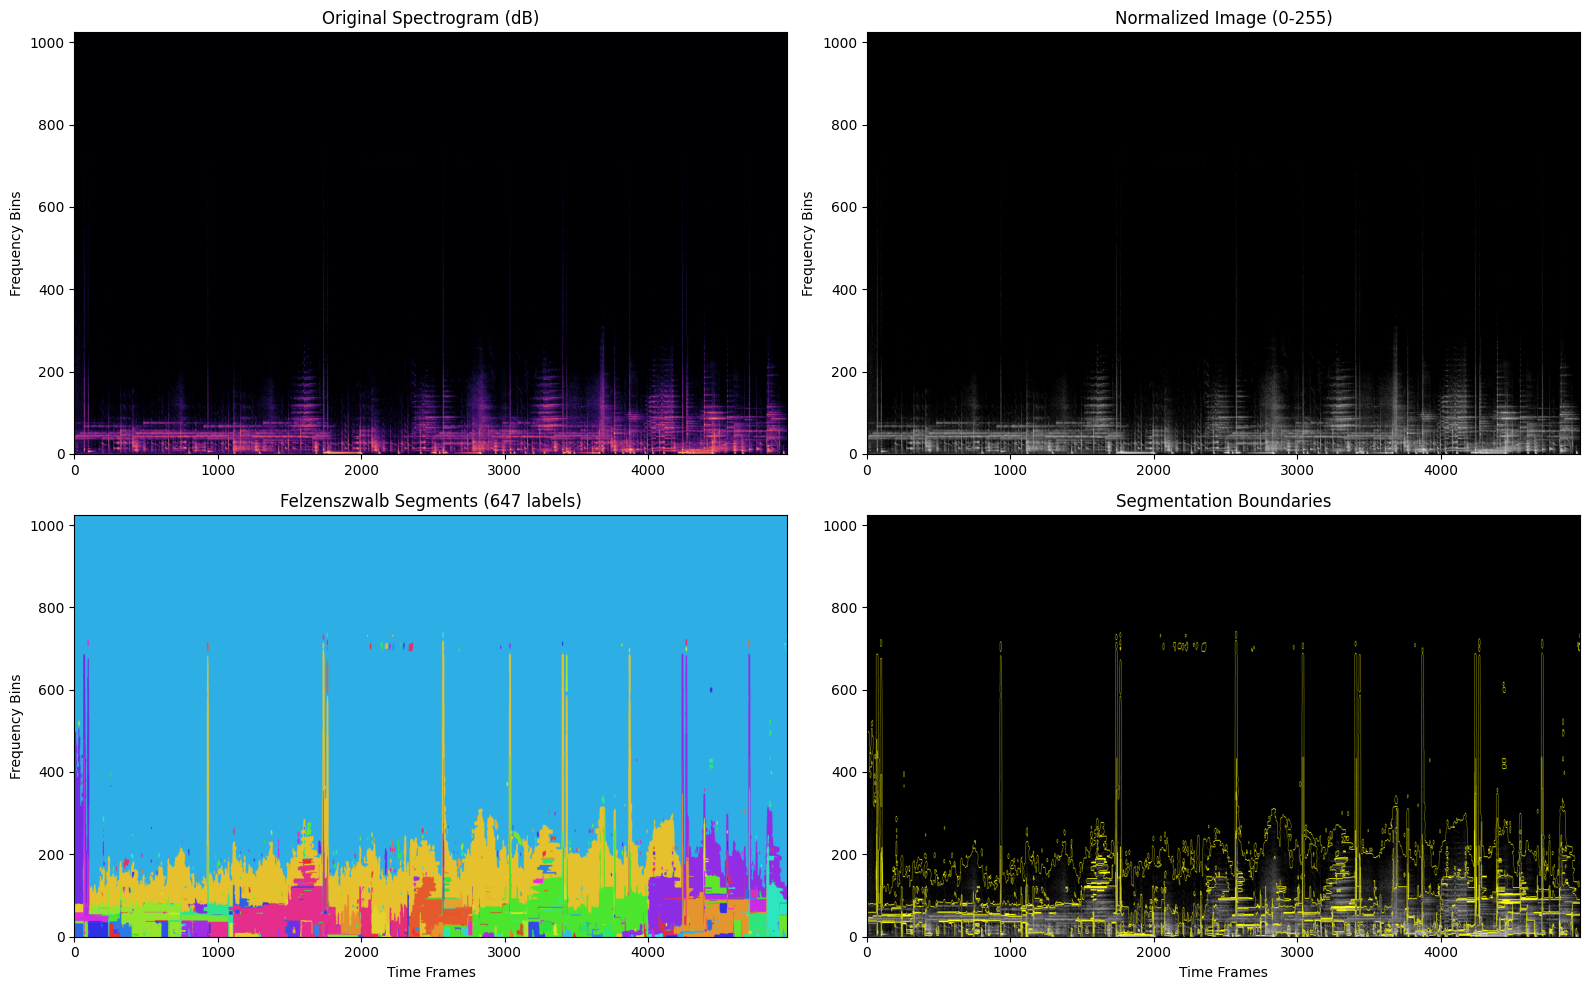


📊 SUMMARY:
   ⏱️  Processing time: 21.12s
   🧩 Total labels found: 647
   🧩 Label regions processed (kept + filtered): 647
   ❌ Filtered out: 596
      └─ By time (< 0.5s duration): 501
      └─ By time (empty): 0
      └─ By energy (< 1.0e-03 ratio): 95
      └─ By area (< 200 pixels): 0
   ✅ Audio chunks saved: 51
   📁 Output directory: chunks_detailed_plainte2/
   🎵 Average chunk duration: 2.67s


In [43]:
import numpy as np
import librosa
import soundfile as sf
import os
import matplotlib.pyplot as plt
from skimage.segmentation import felzenszwalb, mark_boundaries
from skimage.util import img_as_ubyte
import time

def split_audio_felzenszwalb_2d(
    audio_path,
    output_dir="chunks_detailed_{song_path.split('/')[-1].split('.')[0]}",
    n_fft=2048,
    hop_length=512,
    scale=150,
    sigma=3,
    min_size=20,
    min_area_pixels=200,
    min_time_seconds=0.1,
    min_energy_ratio=1e-4,
    max_shapes=None,
):
    """
    🎨 TRUE 2D FELZENSZWALB AUDIO SEGMENTATION (no connected-components)

    This function treats audio spectrograms like images and segments them into irregular 2D shapes.
    Unlike traditional time-based chunking, this extracts spectral "objects" from music.

    HOW IT WORKS:
    1) Compute STFT (frequency × time matrix)
    2) Treat magnitude spectrogram as a grayscale image
    3) Run Felzenszwalb segmentation to get label regions
    4) For EACH LABEL (as a whole), reconstruct its audio by masking the original STFT
    5) Save each label’s audio as its own file

    PARAMETERS:
    - n_fft: Frequency resolution (higher = more freq detail, less time detail)
    - hop_length: Time resolution (lower = more time detail, less freq detail)
    - scale/sigma/min_size: Felzenszwalb controls
    - min_area_pixels / min_time_seconds / min_energy_ratio: filters to skip tiny/short/quiet labels
    """
    start_time = time.time()
    os.makedirs(output_dir, exist_ok=True)

    print(f"🎵 LOADING AUDIO: {audio_path}")

    # 1) Load audio
    y, sr = librosa.load(audio_path, sr=None)
    duration = len(y) / sr
    print(f"   ⏱️  Duration: {duration:.2f}s, Sample Rate: {sr}Hz")

    # 2) Complex STFT and magnitude
    print(f"📊 COMPUTING STFT...")
    print(f"   🔧 n_fft={n_fft}, hop_length={hop_length}")
    D = librosa.stft(y, n_fft=n_fft, hop_length=hop_length, window="hann", center=True)
    S = np.abs(D)  # (freq_bins, time_frames)
    freq_bins, time_frames = S.shape
    print(f"   📏 Spectrogram shape: {freq_bins} freq × {time_frames} time")

    # 3) Log scale + normalize to 0..255 for segmentation
    print(f"🎨 PREPARING IMAGE FOR SEGMENTATION...")
    S_db = librosa.amplitude_to_db(S + 1e-12, ref=np.max)
    S_db_norm = (S_db - S_db.min()) / max(1e-12, (S_db.max() - S_db.min()))
    img = img_as_ubyte(S_db_norm)  # 2D grayscale image
    print(f"   🖼️  Image range: {img.min()}-{img.max()} (8-bit grayscale)")

    # 4) Felzenszwalb segmentation on 2D spectrogram image
    print(f"🧩 RUNNING FELZENSZWALB SEGMENTATION...")
    print(f"   ⚙️  scale={scale}, sigma={sigma}, min_size={min_size}")
    segments = felzenszwalb(img, scale=scale, sigma=sigma, min_size=min_size)
    unique_labels = np.unique(segments)
    print(f"   🎯 Found {len(unique_labels)} initial segments (labels)")

    # 5) Process each label as a single region (no CC)
    print(f"🔍 EXTRACTING 2D SHAPES (one per label)...")
    total_energy = float(S.sum()) + 1e-12
    T = S.shape[1]
    times = librosa.frames_to_time(np.arange(T), sr=sr, hop_length=hop_length)

    saved_paths = []
    shape_index = 0
    filtered_shapes = 0
    filtered_by_area = 0
    filtered_by_energy = 0
    filtered_by_time = 0
    filtered_by_time_empty = 0
    kept_segments = []

    for _, label in enumerate(unique_labels):
        chunk_mask = (segments == label)          # use the label mask directly

        # Filter 1: Time span too short
        time_mask = np.any(chunk_mask, axis=0)
        min_time_frames = int(min_time_seconds * sr / hop_length)
        if time_mask.sum() < min_time_frames:
            filtered_shapes += 1
            filtered_by_time += 1
            continue

        # Filter 2: Energy too low
        energy = float(S[chunk_mask].sum())
        energy_ratio = energy / total_energy
        if energy_ratio < min_energy_ratio:
            filtered_shapes += 1
            filtered_by_energy += 1
            continue

        # Filter 3: Area too small  
        area = int(chunk_mask.sum())
        if area < min_area_pixels:
            filtered_shapes += 1
            filtered_by_area += 1
            continue

        # Calculate shape boundaries
        t0 = int(np.argmax(time_mask))
        t1 = int(len(time_mask) - np.argmax(time_mask[::-1]) - 1)
        freq_mask = np.any(chunk_mask, axis=1)
        f0 = int(np.argmax(freq_mask))
        f1 = int(len(freq_mask) - np.argmax(freq_mask[::-1]) - 1)

        time_span = times[t1] - times[t0] if t1 > t0 else 0
        freq_span = f1 - f0 + 1

        # 🎵 RECONSTRUCT AUDIO: Mask the complex STFT with this label region
        D_masked = D * chunk_mask.astype(D.dtype)
        y_rec = librosa.istft(D_masked, hop_length=hop_length, length=len(y))

        # Slice to the time span of this shape for a concise chunk
        start_samp = int(times[t0] * sr)
        end_samp = min(len(y), int(times[min(t1 + 1, T - 1)] * sr))
        y_seg = y_rec[start_samp:end_samp]
        if y_seg.size == 0:
            filtered_shapes += 1
            filtered_by_time_empty += 1
            continue

        # # # Normalize to avoid clipping
        # peak = np.max(np.abs(y_seg))
        # if peak > 0:
        #     y_seg = 0.98 * y_seg / peak

        # Simple RMS loudness normalization
        # target_rms = 0.1  # target average amplitude (~-20 dBFS, adjust as needed)
        # rms = np.sqrt(np.mean(y_seg**2) + 1e-12)
        # if rms > 0:
        #     y_seg = y_seg * (target_rms / rms)
        
        # Normalize to avoid clipping
        peak = np.max(np.abs(y_seg))      
        if peak > 1.0: 
            y_seg = 0.98 * y_seg / peak
        
        shape_index += 1
        filename = f"felzen_shape_{shape_index:03d}_t{(t1 - t0 + 1)}_f{freq_span}.wav"
        out_path = os.path.join(output_dir, filename)
        sf.write(out_path, y_seg, sr)
        saved_paths.append(out_path)
        print(f"   🎵 rms: {np.sqrt(np.mean(y_seg**2)):.2f}")

        kept_segments.append({
            "idx": int(shape_index - 1),
            "label": int(label),
            "t0_frame": int(t0),
            "t1_frame": int(t1),
            "t0_sec": float(times[t0]),
            "t1_sec": float(times[min(t1 + 1, T - 1)]),
            "f0_bin": int(f0),
            "f1_bin": int(f1),
            "freq_span": int(freq_span),
            "time_span_sec": float(time_span),
            "energy_ratio": float(energy_ratio),
            "path": out_path,
        })

        print(f"   🎵 Shape {shape_index:2d}: {time_span:.2f}s × {freq_span:3d}bins, energy={energy_ratio:.1e} → {filename}")

        if max_shapes is not None and shape_index >= max_shapes:
            break

    # 6) Create and display visualization
    print(f"📊 CREATING VISUALIZATIONS...")

    fig, axes = plt.subplots(2, 2, figsize=(16, 10))

    # Original spectrogram
    axes[0,0].imshow(S_db, aspect='auto', origin='lower', cmap='magma')
    axes[0,0].set_title('Original Spectrogram (dB)')
    axes[0,0].set_ylabel('Frequency Bins')

    # Normalized image for segmentation
    axes[0,1].imshow(img, aspect='auto', origin='lower', cmap='gray')
    axes[0,1].set_title('Normalized Image (0-255)')
    axes[0,1].set_ylabel('Frequency Bins')

    from matplotlib.colors import ListedColormap, hsv_to_rgb
    n_labels = len(unique_labels)
    hsv_colors = [(i / n_labels, 0.8, 0.9) for i in range(n_labels)]
    rgb_colors = [hsv_to_rgb(c) for c in hsv_colors]
    np.random.seed(11)  # Fixed seed for consistent colors
    np.random.shuffle(rgb_colors)  # shuffle to avoid adjacent similar colors
    unique_cmap = ListedColormap(rgb_colors)
    axes[1,0].imshow(segments, aspect='auto', origin='lower', cmap=unique_cmap)
    # # Segmentation labels
    # axes[1,0].imshow(segments, aspect='auto', origin='lower', cmap='tab20')
    axes[1,0].set_title(f'Felzenszwalb Segments ({len(unique_labels)} labels)')
    axes[1,0].set_xlabel('Time Frames')
    axes[1,0].set_ylabel('Frequency Bins')

    # Boundaries overlay
    boundary_img = mark_boundaries(np.dstack([S_db_norm]*3), segments)
    axes[1,1].imshow(boundary_img, aspect='auto', origin='lower')
    axes[1,1].set_title('Segmentation Boundaries')
    axes[1,1].set_xlabel('Time Frames')

    plt.tight_layout()
    viz_path = os.path.join(output_dir, "felzenszwalb_analysis.png")
    plt.savefig(viz_path, dpi=160, bbox_inches='tight')
    print(f"   💾 Saved visualization: {viz_path}")

    # Also save as PDF
    pdf_viz_path = os.path.join(output_dir, "00_felzenszwalb_analysis.pdf")
    plt.savefig(pdf_viz_path, format='pdf', dpi=300, bbox_inches='tight')
    print(f"   📄 Saved PDF: {pdf_viz_path}")
    plt.show()

    # Summary statistics
    total_time = time.time() - start_time
    print(f"\n📊 SUMMARY:")
    print(f"   ⏱️  Processing time: {total_time:.2f}s")
    print(f"   🧩 Total labels found: {len(unique_labels)}")
    print(f"   🧩 Label regions processed (kept + filtered): {shape_index + filtered_shapes}")
    print(f"   ❌ Filtered out: {filtered_shapes}")
    print(f"      └─ By time (< {min_time_seconds}s duration): {filtered_by_time}")
    print(f"      └─ By time (empty): {filtered_by_time_empty}")
    print(f"      └─ By energy (< {min_energy_ratio:.1e} ratio): {filtered_by_energy}")
    print(f"      └─ By area (< {min_area_pixels} pixels): {filtered_by_area}")
    print(f"   ✅ Audio chunks saved: {shape_index}")
    print(f"   📁 Output directory: {output_dir}/")
    if saved_paths:
        print(f"   🎵 Average chunk duration: {np.mean([len(sf.read(p)[0])/sr for p in saved_paths[:5]]):.2f}s")
    else:
        print(f"   🎵 Average chunk duration: n/a")

    return saved_paths, kept_segments

# 🚀 RUN THE SEGMENTATION
print("🎨 STARTING FELZENSZWALB 2D AUDIO SEGMENTATION")
print("=" * 60)
song_path = "../thingies/clips/plainte2.mp3"
shapes, kept_segments = split_audio_felzenszwalb_2d(
    song_path,
    output_dir=f"chunks_detailed_{song_path.split('/')[-1].split('.')[0]}",
    scale=150,      # Lower = more segments
    sigma=3,        # Lower = sharper boundaries
    min_size=20,    # Larger = fewer tiny segments
    max_shapes=100,  # Limit output for testing
    min_area_pixels=200,
    min_time_seconds=0.5,  # Minimum duration in seconds
    min_energy_ratio=1e-3
)

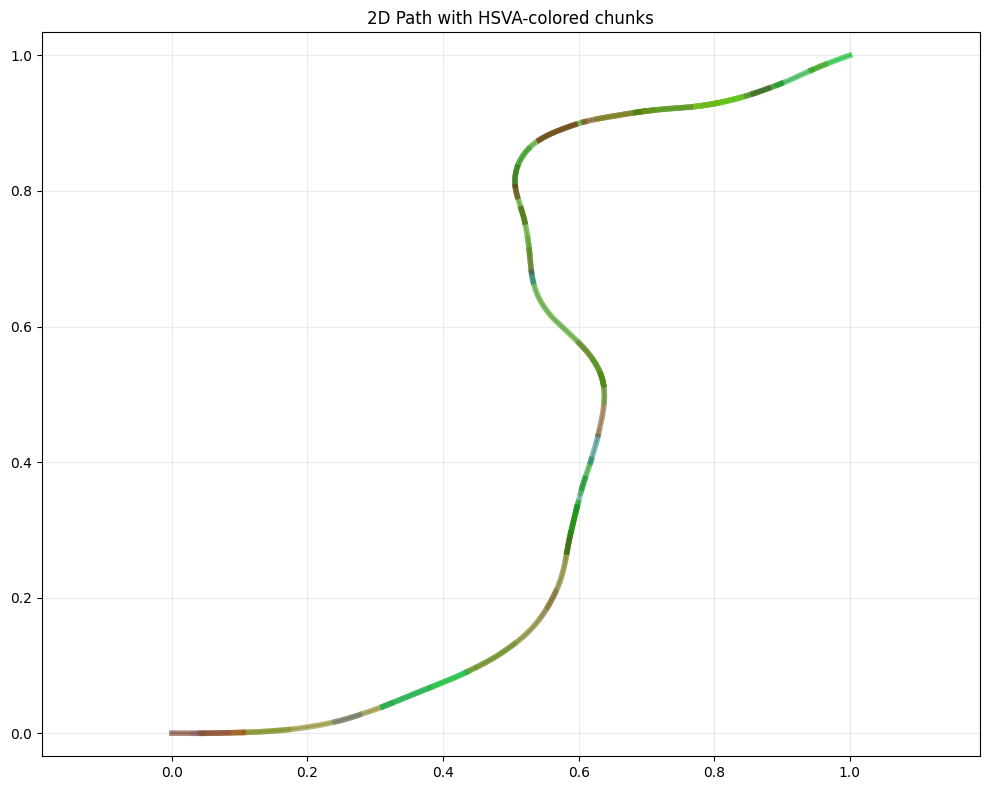

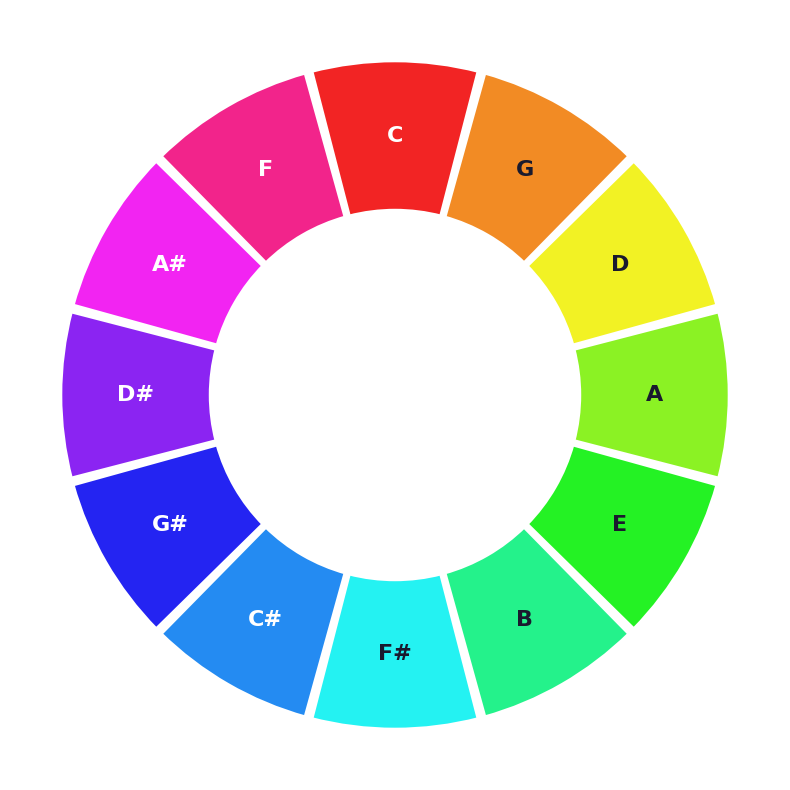

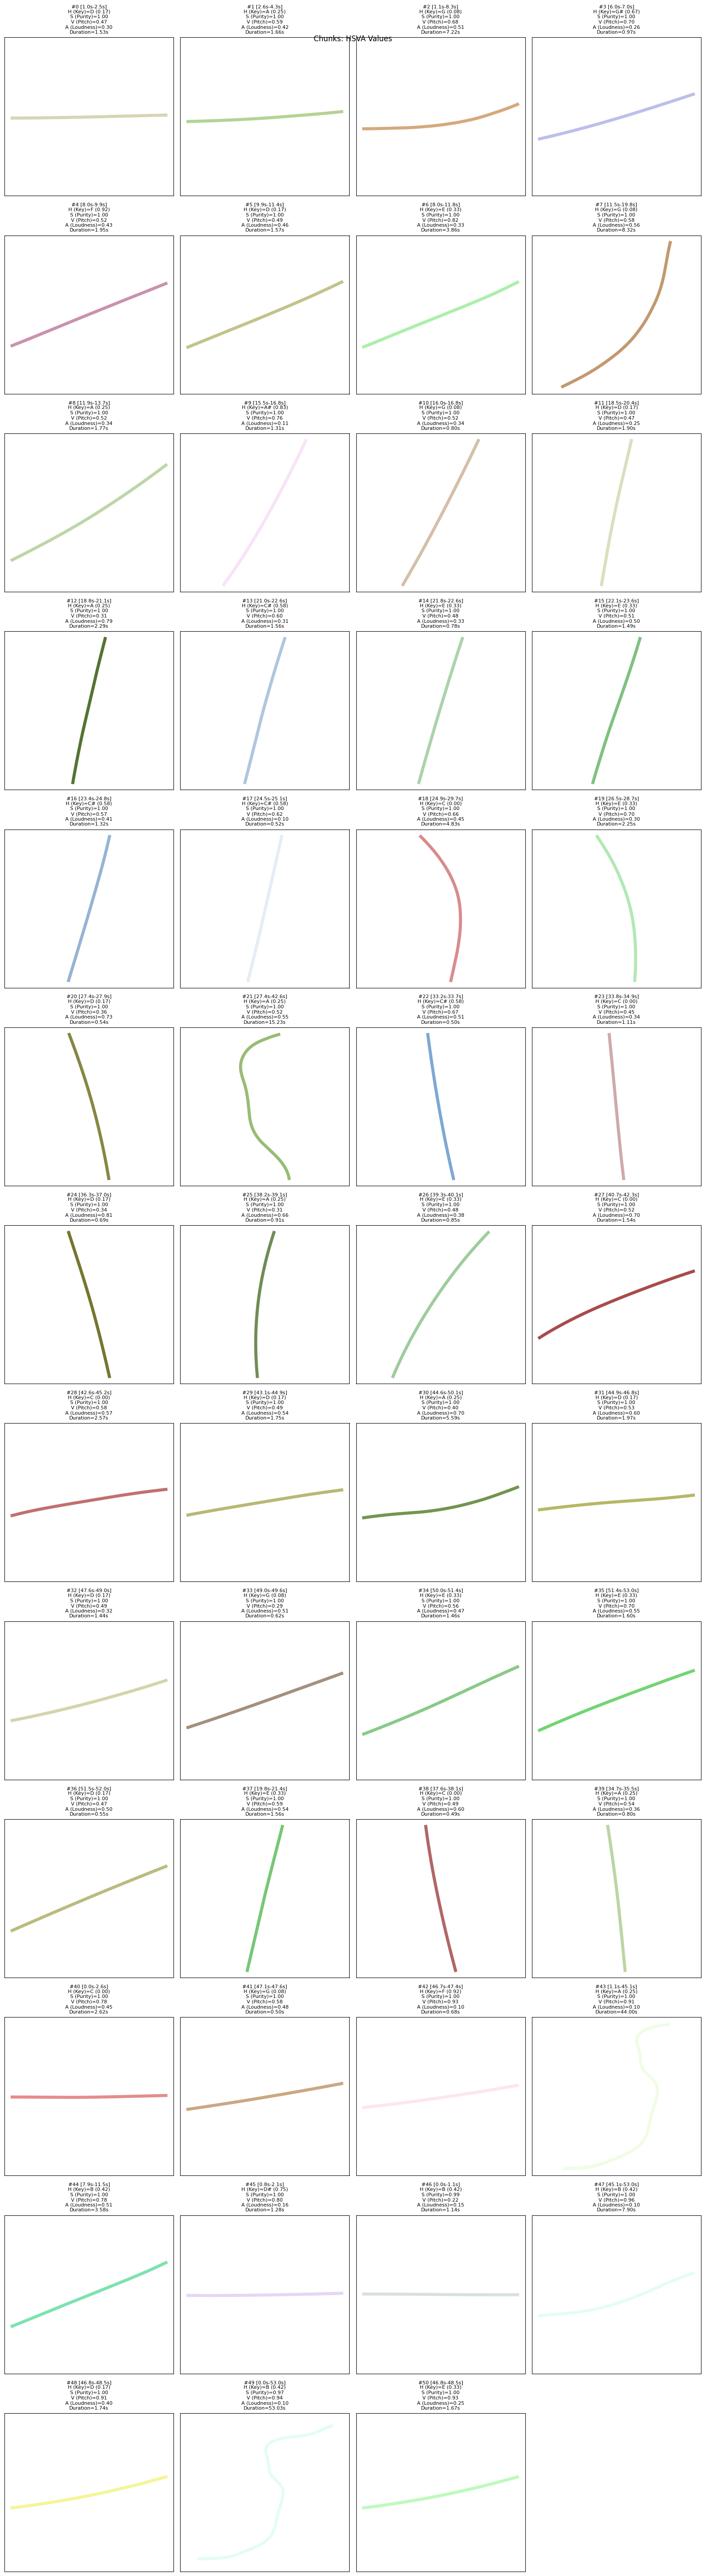

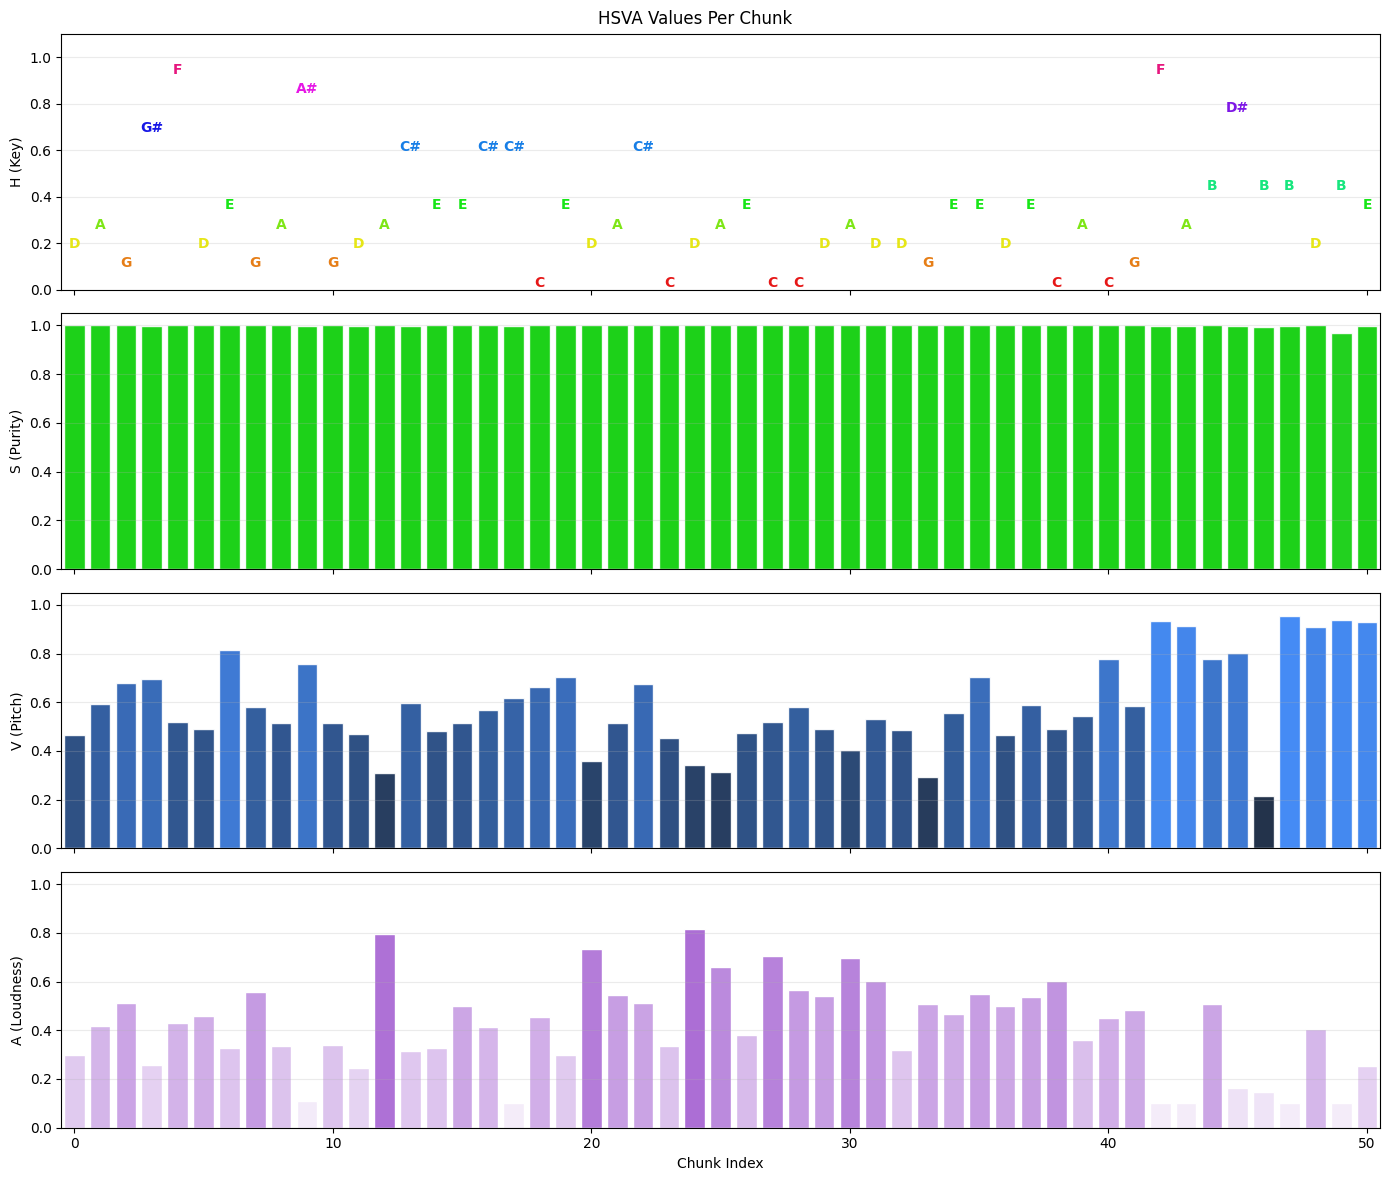

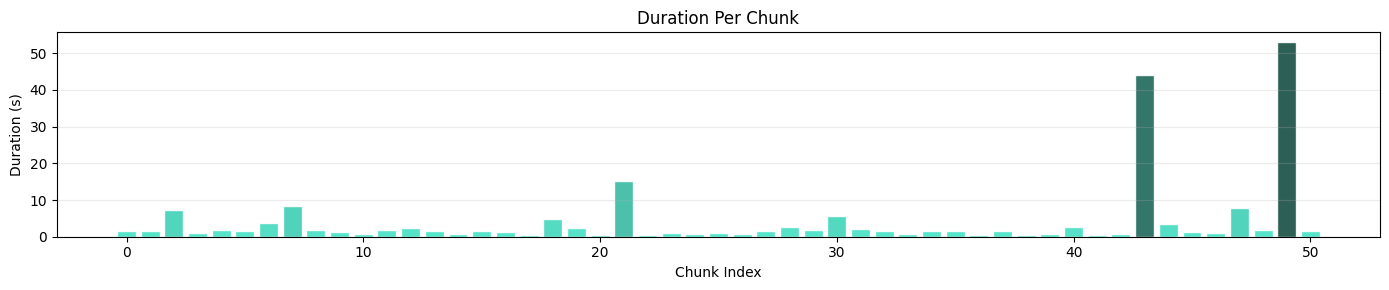


📊 Summary (51 chunks):
   H (Key):      0.30
   S (Purity):   1.00
   V (Pitch):    0.59
   A (Loudness): 0.42
   Duration:     4.08s total=207.86s


In [12]:
import numpy as np
import matplotlib.pyplot as plt
import colorsys
import sys
sys.path.insert(0, '..')

from utils.sound_utils import create_2d_path_visualization
from matplotlib.patches import Wedge
import soundfile as sf

# Circle of fifths for key names
CIRCLE_ORDER = [0, 7, 2, 9, 4, 11, 6, 1, 8, 3, 10, 5]
PITCH_NAMES = ["C", "C#", "D", "D#", "E", "F", "F#", "G", "G#", "A", "A#", "B"]

def hue_to_key_name(h):
    idx = int(h * 12) % 12
    pitch_idx = CIRCLE_ORDER[idx]
    return PITCH_NAMES[pitch_idx]

# Run visualization
X, Y, curve_chunks_2d, curve_profiles_2d = create_2d_path_visualization(
    kept_segments,
    song_path,
    points_per_second=100,
    resampled_points_per_chunk=128,
    show_plots=False
)

for i, chunk in enumerate(curve_chunks_2d):
    seg = kept_segments[i]
    chunk["duration"] = seg["t1_sec"] - seg["t0_sec"]

overlay_idxs = list(range(min(100, len(curve_chunks_2d))))

# Figure 1: Full path
fig1, ax1 = plt.subplots(1, 1, figsize=(10, 8))
ax1.plot(X, Y, color="#333", linewidth=1.5, alpha=0.3)
for i in overlay_idxs:
    chunk = curve_chunks_2d[i]
    ax1.plot(chunk["x"], chunk["y"], linewidth=4.0, color=chunk["color_rgba"])
ax1.set_title("2D Path with HSVA-colored chunks")
ax1.axis('equal')
ax1.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()

# Figure 2: Circle of fifths
fig_cof, ax_cof = plt.subplots(1, 1, figsize=(8, 8), facecolor='#FFFFFF')
ax_cof.set_facecolor('#FFFFFF')

R_outer, R_inner = 1.0, 0.55

for k in range(12):
    pitch = CIRCLE_ORDER[k]
    H = k / 12.0
    r_col, g_col, b_col = colorsys.hsv_to_rgb(H, 0.85, 0.95)

    theta_center = 90.0 - k * 30.0
    theta1, theta2 = theta_center - 14.5, theta_center + 14.5

    # Wedge
    wedge = Wedge((0, 0), R_outer, theta1, theta2, width=R_outer - R_inner,
                facecolor=(r_col, g_col, b_col), edgecolor='#FFFFFF', linewidth=3)
    ax_cof.add_patch(wedge)

    # Letter inside wedge
    theta_mid = np.deg2rad(theta_center)
    r_text = (R_outer + R_inner) / 2
    tx, ty = r_text * np.cos(theta_mid), r_text * np.sin(theta_mid)

    brightness = 0.299 * r_col + 0.587 * g_col + 0.114 * b_col
    text_color = '#1a1a2e' if brightness > 0.6 else 'white'

    ax_cof.text(tx, ty, PITCH_NAMES[pitch], ha='center', va='center',
                fontsize=16, fontweight='bold', color=text_color)


ax_cof.set_xlim(-1.15, 1.15)
ax_cof.set_ylim(-1.15, 1.15)
ax_cof.set_aspect('equal')
ax_cof.axis('off')
plt.tight_layout()
plt.show()


# Figure 3: Grid with HSVA labels
N = len(overlay_idxs)
if N > 0:
    cols = 4
    rows = int(np.ceil(N / cols))
    fig2, axes2 = plt.subplots(rows, cols, figsize=(cols * 4, rows * 4.5))
    axes2 = np.atleast_2d(axes2).reshape(rows, cols)

    for idx in range(rows * cols):
        r = idx // cols
        c = idx % cols
        ax = axes2[r, c]

        if idx < N:
            k = overlay_idxs[idx]
            chunk = curve_chunks_2d[k]
            rgba = chunk["color_rgba"]
            r_val, g_val, b_val, a_val = rgba
            h, s, v = colorsys.rgb_to_hsv(r_val, g_val, b_val)
            key_name = hue_to_key_name(h)

            ax.plot(chunk["x_resampled"], chunk["y_resampled"], color=rgba, linewidth=5.0)

            title = (
                f"#{k} [{chunk['t_start']:.1f}s-{chunk['t_end']:.1f}s]\n"
                f"H (Key)={key_name} ({h:.2f})\n"
                f"S (Purity)={s:.2f}\n"
                f"V (Pitch)={v:.2f}\n"
                f"A (Loudness)={a_val:.2f}\n"
                f"Duration={chunk['duration']:.2f}s"
            )
            ax.set_title(title, fontsize=8, linespacing=1.2)
            ax.axis('equal')
            ax.grid(True, alpha=0.25)
            ax.set_xticks([])
            ax.set_yticks([])
        else:
            ax.axis('off')

    fig2.suptitle("Chunks: HSVA Values", fontsize=12)
    plt.tight_layout()
    plt.show()

# Collect HSVA data
chunk_ids = list(range(len(curve_chunks_2d)))
hsva_data = []
key_names_list = []
for chunk in curve_chunks_2d:
    r_val, g_val, b_val, a_val = chunk["color_rgba"]
    h, s, v = colorsys.rgb_to_hsv(r_val, g_val, b_val)
    hsva_data.append((h, s, v, a_val))
    key_names_list.append(hue_to_key_name(h))
hsva_data = np.array(hsva_data)

# Figure 4: HSVA per chunk
fig3, axes3 = plt.subplots(4, 1, figsize=(14, 12), sharex=True)

# Hue - colored key letters
ax_h = axes3[0]
for j, (h_val, key) in enumerate(zip(hsva_data[:, 0], key_names_list)):
    color = colorsys.hsv_to_rgb(h_val, 0.9, 0.9)
    ax_h.text(j, h_val, key, ha='center', va='bottom', fontsize=10, fontweight='bold', color=color)
ax_h.set_xlim(-0.5, len(chunk_ids) - 0.5)
ax_h.set_ylim(0, 1.1)
ax_h.set_ylabel('H (Key)')
ax_h.grid(True, alpha=0.25, axis='y')

# Saturation - gray to green
sat_colors = [colorsys.hsv_to_rgb(0.33, s, 0.8) for s in hsva_data[:, 1]]
axes3[1].bar(chunk_ids, hsva_data[:, 1], color=sat_colors, edgecolor='white', alpha=0.9)
axes3[1].set_ylabel('S (Purity)')
axes3[1].set_ylim(0, 1.05)
axes3[1].grid(True, alpha=0.25, axis='y')

# Value - dark to bright blue
val_colors = [colorsys.hsv_to_rgb(0.6, 0.8, v) for v in hsva_data[:, 2]]
axes3[2].bar(chunk_ids, hsva_data[:, 2], color=val_colors, edgecolor='white', alpha=0.9)
axes3[2].set_ylabel('V (Pitch)')
axes3[2].set_ylim(0, 1.05)
axes3[2].grid(True, alpha=0.25, axis='y')

# Alpha - transparent to opaque purple
alpha_colors = [(0.6, 0.3, 0.8, a) for a in hsva_data[:, 3]]
axes3[3].bar(chunk_ids, hsva_data[:, 3], color=alpha_colors, edgecolor='white')
axes3[3].set_ylabel('A (Loudness)')
axes3[3].set_ylim(0, 1.05)
axes3[3].set_xlabel('Chunk Index')
axes3[3].grid(True, alpha=0.25, axis='y')

fig3.suptitle("HSVA Values Per Chunk", fontsize=12)
plt.tight_layout()
plt.show()

# Figure 5: Duration - dark if high
fig4, ax4 = plt.subplots(figsize=(14, 3))
durations = [chunk["duration"] for chunk in curve_chunks_2d]
max_dur = max(durations)
dur_colors = [colorsys.hsv_to_rgb(0.47, 0.7, 0.9 - 0.6 * (d / max_dur)) for d in durations]  # dark if high
ax4.bar(chunk_ids, durations, color=dur_colors, edgecolor='white', alpha=0.9)
ax4.set_ylabel('Duration (s)')
ax4.set_xlabel('Chunk Index')
ax4.grid(True, alpha=0.25, axis='y')
ax4.set_title("Duration Per Chunk")
plt.tight_layout()
plt.show()

print(f"\n📊 Summary ({len(curve_chunks_2d)} chunks):")
print(f"   H (Key):      {np.mean(hsva_data[:,0]):.2f}")
print(f"   S (Purity):   {np.mean(hsva_data[:,1]):.2f}")
print(f"   V (Pitch):    {np.mean(hsva_data[:,2]):.2f}")
print(f"   A (Loudness): {np.mean(hsva_data[:,3]):.2f}")
print(f"   Duration:     {np.mean(durations):.2f}s total={sum(durations):.2f}s")

In [ ]:
# 📄 EXPORT EACH PLOT TO SEPARATE PDF FILES

import os

# Create PDFs directory
output_dir = "."
pdf_output_dir = os.path.join(output_dir, "pdfs")
os.makedirs(pdf_output_dir, exist_ok=True)

print("📄 EXPORTING PLOTS TO PDF...")

# Export Figure 1: Full path
fig1.savefig(os.path.join(pdf_output_dir, "01_full_path_with_chunks.pdf"),
            format='pdf', bbox_inches='tight', dpi=300)
print(f"   ✅ Saved: 01_full_path_with_chunks.pdf")

# Export Figure 2: Circle of fifths
fig_cof.savefig(os.path.join(pdf_output_dir, "02_circle_of_fifths.pdf"),
                format='pdf', bbox_inches='tight', dpi=300)
print(f"   ✅ Saved: 02_circle_of_fifths.pdf")

# Export Figure 3: Grid with HSVA labels
if N > 0:
    fig2.savefig(os.path.join(pdf_output_dir, "03_chunks_hsva_grid.pdf"),
                format='pdf', bbox_inches='tight', dpi=300)
    print(f"   ✅ Saved: 03_chunks_hsva_grid.pdf")

# Export Figure 4: HSVA per chunk
fig3.savefig(os.path.join(pdf_output_dir, "04_hsva_values_per_chunk.pdf"),
            format='pdf', bbox_inches='tight', dpi=300)
print(f"   ✅ Saved: 04_hsva_values_per_chunk.pdf")

# Export Figure 5: Duration
fig4.savefig(os.path.join(pdf_output_dir, "05_duration_per_chunk.pdf"),
            format='pdf', bbox_inches='tight', dpi=300)
print(f"   ✅ Saved: 05_duration_per_chunk.pdf")

print(f"\n📁 All PDFs saved to: {pdf_output_dir}/")
print(f"   Total files: 5 PDFs")

In [ ]:
# 🎨 GRID OF ALL FELZEN CHUNKS FROM SPECTROGRAM (COLORED)

# Re-load audio and recreate spectrogram to visualize chunks
y, sr = librosa.load(song_path, sr=None)
D = librosa.stft(y, n_fft=2048, hop_length=512, window="hann", center=True)
S = np.abs(D)
S_db = librosa.amplitude_to_db(S + 1e-12, ref=np.max)

# Recreate segmentation to get labels and colors
from skimage.util import img_as_ubyte
S_db_norm = (S_db - S_db.min()) / max(1e-12, (S_db.max() - S_db.min()))
img = img_as_ubyte(S_db_norm)
segments = felzenszwalb(img, scale=150, sigma=3, min_size=20)
unique_labels = np.unique(segments)

# Create the SAME color mapping as in the original visualization
# Use the same random seed to get identical shuffle as cell 1
from matplotlib.colors import hsv_to_rgb
n_labels = len(unique_labels)
hsv_colors = [(i / n_labels, 0.8, 0.9) for i in range(n_labels)]
rgb_colors = [hsv_to_rgb(c) for c in hsv_colors]
np.random.seed(11)  # Fixed seed to match cell 1
np.random.shuffle(rgb_colors)

# Create a mapping from label to color
label_to_color = {label: rgb_colors[i % len(rgb_colors)] for i, label in enumerate(unique_labels)}

# Use ALL segments to display
N = len(kept_segments)
segments_to_show = kept_segments

# Create grid with same layout as curves grid
cols = 4
rows = int(np.ceil(N / cols))
fig_grid, axes_grid = plt.subplots(rows, cols, figsize=(cols * 4, rows * 4.5), 
                                    subplot_kw={'aspect': 'auto'})
axes_grid = np.atleast_2d(axes_grid).reshape(rows, cols)

for idx in range(rows * cols):
    r = idx // cols
    c = idx % cols
    ax = axes_grid[r, c]
    
    if idx < N:
        seg = segments_to_show[idx]
        label = seg["label"]
        
        # Get the color for this segment's label
        color = label_to_color.get(label, (1, 1, 1))
        
        # Extract the chunk from the spectrogram
        t0, t1 = seg["t0_frame"], seg["t1_frame"]
        f0, f1 = seg["f0_bin"], seg["f1_bin"]
        
        # Create mask for this segment
        chunk_mask = (segments == label)
        
        # Extract just this segment's region at FULL RESOLUTION
        chunk_region = chunk_mask[f0:f1+1, t0:t1+1]
        chunk_height, chunk_width = chunk_region.shape
        
        # Create RGB image with WHITE background at full resolution
        colored_chunk = np.ones((chunk_height, chunk_width, 3))
        colored_chunk[chunk_region] = color
        
        # Show the colored chunk at full resolution
        im = ax.imshow(colored_chunk, origin='lower', interpolation='bilinear')
        
        # Set white background for the axes
        ax.set_facecolor('white')
        
        # Zoom to fit this specific chunk with a small margin
        margin = 0.05  # 5% margin
        ax.set_xlim(-margin * chunk_width, chunk_width * (1 + margin))
        ax.set_ylim(-margin * chunk_height, chunk_height * (1 + margin))
        
        # Title with segment info - same format as curves grid
        title = (f"#{idx} [{seg['t0_sec']:.1f}s-{seg['t1_sec']:.1f}s]\n"
                f"Label {label}\n"
                f"Freq: {seg['f0_bin']}-{seg['f1_bin']}\n"
                f"Duration={seg['time_span_sec']:.2f}s")
        ax.set_title(title, fontsize=8, linespacing=1.2)
        ax.set_xticks([])
        ax.set_yticks([])
    else:
        ax.axis('off')

fig_grid.suptitle("Felzen Chunks: Colored Segments", fontsize=12)
plt.tight_layout()

# Save to PDF
pdf_path_grid = os.path.join('.', "06_felzen_chunks_grid_colored.pdf")
plt.savefig(pdf_path_grid, format='pdf', bbox_inches='tight', dpi=300)
print(f"📄 Saved: {pdf_path_grid}")

plt.show()

print(f"\n✅ Displayed {N} felzenszwalb chunks with segment colors")

In [ ]:
# 🎨 GRID OF ALL FELZEN CHUNKS - SPECTROGRAM VIEW

# Create grid with same layout
cols = 4
rows = int(np.ceil(N / cols))
fig_spec, axes_spec = plt.subplots(rows, cols, figsize=(cols * 4, rows * 4.5), 
                                    subplot_kw={'aspect': 'auto'})
axes_spec = np.atleast_2d(axes_spec).reshape(rows, cols)

for idx in range(rows * cols):
    r = idx // cols
    c = idx % cols
    ax = axes_spec[r, c]
    
    if idx < N:
        seg = segments_to_show[idx]
        label = seg["label"]
        
        # Extract the chunk from the spectrogram
        t0, t1 = seg["t0_frame"], seg["t1_frame"]
        f0, f1 = seg["f0_bin"], seg["f1_bin"]
        
        # Create mask for this segment
        chunk_mask = (segments == label)
        
        # Extract just this segment's region at FULL RESOLUTION
        chunk_region = chunk_mask[f0:f1+1, t0:t1+1]
        chunk_height, chunk_width = chunk_region.shape
        
        # Extract SPECTROGRAM data for this chunk
        chunk_spec = S_db[f0:f1+1, t0:t1+1].copy()
        
        # Mask out non-chunk areas (set to minimum value)
        chunk_spec[~chunk_region] = S_db.min()
        
        # Show the spectrogram chunk at full resolution (same settings as colored version)
        im = ax.imshow(chunk_spec, origin='lower', cmap='magma', interpolation='bilinear')
        
        # Set white background for the axes
        ax.set_facecolor('white')
        
        # Zoom to fit this specific chunk with a small margin (SAME as colored version)
        margin = 0.05  # 5% margin
        ax.set_xlim(-margin * chunk_width, chunk_width * (1 + margin))
        ax.set_ylim(-margin * chunk_height, chunk_height * (1 + margin))
        
        # Title with segment info - same format as curves grid
        title = (f"#{idx} [{seg['t0_sec']:.1f}s-{seg['t1_sec']:.1f}s]\n"
                f"Label {label}\n"
                f"Freq: {seg['f0_bin']}-{seg['f1_bin']}\n"
                f"Duration={seg['time_span_sec']:.2f}s")
        ax.set_title(title, fontsize=8, linespacing=1.2)
        ax.set_xticks([])
        ax.set_yticks([])
    else:
        ax.axis('off')

fig_spec.suptitle("Felzen Chunks: Spectrogram View", fontsize=12)
plt.tight_layout()

# Save to PDF
pdf_path_spec = os.path.join('.', "07_felzen_chunks_grid_spectrogram.pdf")
plt.savefig(pdf_path_spec, format='pdf', bbox_inches='tight', dpi=300)
print(f"📄 Saved: {pdf_path_spec}")

plt.show()

print(f"\n✅ Displayed {N} felzenszwalb chunks with spectrogram data")

🎨 STARTING FELZENSZWALB 2D MEL AUDIO SEGMENTATION
🎵 LOADING AUDIO: ../thingies/clips/plainte2.mp3
   ⏱️  Duration: 53.04s, Sample Rate: 48000Hz
📊 COMPUTING STFT...
   🔧 n_fft=2048, hop_length=512
   📏 STFT shape: 1025 freq × 4973 time
🎵 COMPUTING MEL SPECTROGRAM...
   🔧 n_mels=128, fmin=0, fmax=24000.0
   📏 Mel shape: 128 mel_bins × 4973 time
🎨 PREPARING MEL IMAGE FOR SEGMENTATION...
   🖼️  Image range: 0-255 (8-bit grayscale)
🧩 RUNNING FELZENSZWALB SEGMENTATION...
   ⚙️  scale=150, sigma=1, min_size=20
   🎯 Found 796 initial segments (labels)
🔍 EXTRACTING 2D SHAPES (one per label)...
   🎵 rms: 0.01
   🎵 Shape  1: 2.55s × 115 mel_bins, energy=1.1e-02 → felzen_mel_shape_001_t240_mel115.wav
   🎵 rms: 0.00
   🎵 Shape  2: 0.48s ×  25 mel_bins, energy=1.0e-03 → felzen_mel_shape_002_t46_mel25.wav
   🎵 rms: 0.01
   🎵 Shape  3: 1.53s ×  73 mel_bins, energy=1.0e-02 → felzen_mel_shape_003_t144_mel73.wav
   🎵 rms: 0.01
   🎵 Shape  4: 4.39s ×  75 mel_bins, energy=3.2e-02 → felzen_mel_shape_004_t41

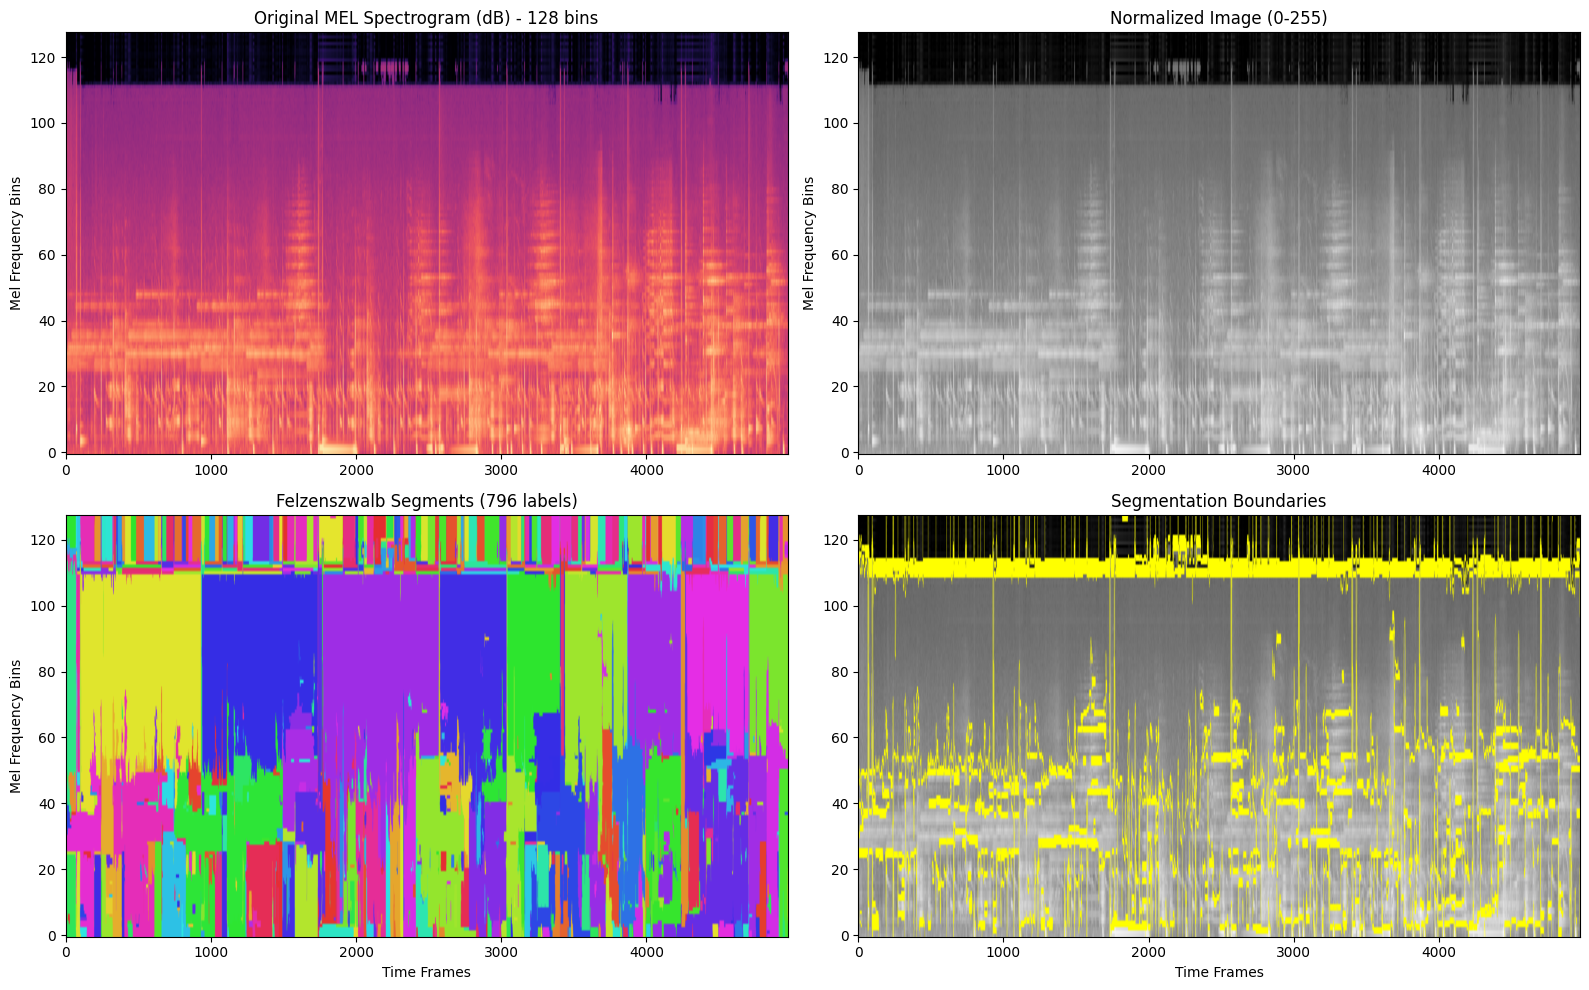


📊 SUMMARY:
   ⏱️  Processing time: 7.85s
   🎵 Mel bins: 128 (vs 1025 STFT bins)
   🧩 Total labels found: 796
   🧩 Label regions processed (kept + filtered): 796
   ❌ Filtered out: 729
      └─ By time (< 0.5s duration): 506
      └─ By time (empty): 0
      └─ By energy (< 1.0e-03 ratio): 219
      └─ By area (< 200 pixels): 4
   ✅ Audio chunks saved: 67
   📁 Output directory: chunks_mel_plainte2/
   🎵 Average chunk duration: 1.90s


In [52]:
import numpy as np
import librosa
import soundfile as sf
import os
import matplotlib.pyplot as plt
from skimage.segmentation import felzenszwalb, mark_boundaries
from skimage.util import img_as_ubyte
import time

def split_audio_felzenszwalb_2d_mel(
    audio_path,
    output_dir="chunks_detailed_{song_path.split('/')[-1].split('.')[0]}",
    n_fft=2048,
    hop_length=512,
    n_mels=128,  # NEW: Number of mel frequency bins
    fmin=0,      # NEW: Minimum frequency (Hz)
    fmax=None,   # NEW: Maximum frequency (Hz), None = sr/2
    scale=150,
    sigma=3,
    min_size=20,
    min_area_pixels=200,
    min_time_seconds=0.1,
    min_energy_ratio=1e-4,
    max_shapes=None,
):
    """
    🎨 TRUE 2D FELZENSZWALB AUDIO SEGMENTATION with MEL SPECTROGRAM
    
    This function uses a perceptually-motivated Mel spectrogram for segmentation,
    which gives logarithmic frequency spacing (more like human hearing).
    
    HOW IT WORKS:
    1) Compute STFT (frequency × time matrix) - LINEAR frequency bins
    2) Convert to MEL spectrogram (perceptual frequency scale)
    3) Run Felzenszwalb segmentation on MEL spectrogram
    4) Map MEL mask back to STFT bins
    5) Reconstruct audio by masking the original complex STFT
    6) Save each label's audio as its own file
    
    PARAMETERS:
    - n_fft: STFT frequency resolution
    - hop_length: STFT time resolution
    - n_mels: Number of mel frequency bins (fewer = more compression of high freqs)
    - fmin/fmax: Frequency range for mel filterbank
    - scale/sigma/min_size: Felzenszwalb controls
    - min_area_pixels / min_time_seconds / min_energy_ratio: filters
    """
    start_time = time.time()
    os.makedirs(output_dir, exist_ok=True)

    print(f"🎵 LOADING AUDIO: {audio_path}")

    # 1) Load audio
    y, sr = librosa.load(audio_path, sr=None)
    duration = len(y) / sr
    print(f"   ⏱️  Duration: {duration:.2f}s, Sample Rate: {sr}Hz")

    # 2) Complex STFT (needed for reconstruction)
    print(f"📊 COMPUTING STFT...")
    print(f"   🔧 n_fft={n_fft}, hop_length={hop_length}")
    D = librosa.stft(y, n_fft=n_fft, hop_length=hop_length, window="hann", center=True)
    S = np.abs(D)  # (freq_bins, time_frames) - LINEAR frequency
    freq_bins, time_frames = S.shape
    print(f"   📏 STFT shape: {freq_bins} freq × {time_frames} time")

    # 3) Mel spectrogram (perceptual frequency scale)
    print(f"🎵 COMPUTING MEL SPECTROGRAM...")
    print(f"   🔧 n_mels={n_mels}, fmin={fmin}, fmax={fmax or sr/2}")
    M = librosa.feature.melspectrogram(
        S=S, sr=sr, n_mels=n_mels, fmin=fmin, fmax=fmax
    )  # (n_mels, time_frames) - LOG frequency
    print(f"   📏 Mel shape: {M.shape[0]} mel_bins × {M.shape[1]} time")

    # Get mel filterbank for mapping mel bins -> STFT bins
    mel_basis = librosa.filters.mel(
        sr=sr, n_fft=n_fft, n_mels=n_mels, fmin=fmin, fmax=fmax
    )  # (n_mels, freq_bins) - each row shows which STFT bins contribute to a mel bin

    # 4) Log scale + normalize to 0..255 for segmentation
    print(f"🎨 PREPARING MEL IMAGE FOR SEGMENTATION...")
    M_db = librosa.power_to_db(M, ref=np.max)
    M_db_norm = (M_db - M_db.min()) / max(1e-12, (M_db.max() - M_db.min()))
    img = img_as_ubyte(M_db_norm)  # 2D grayscale image
    print(f"   🖼️  Image range: {img.min()}-{img.max()} (8-bit grayscale)")

    # 5) Felzenszwalb segmentation on MEL spectrogram
    print(f"🧩 RUNNING FELZENSZWALB SEGMENTATION...")
    print(f"   ⚙️  scale={scale}, sigma={sigma}, min_size={min_size}")
    segments = felzenszwalb(img, scale=scale, sigma=sigma, min_size=min_size)
    unique_labels = np.unique(segments)
    print(f"   🎯 Found {len(unique_labels)} initial segments (labels)")

    # 6) Process each label
    print(f"🔍 EXTRACTING 2D SHAPES (one per label)...")
    total_energy = float(M.sum()) + 1e-12
    T = M.shape[1]
    times = librosa.frames_to_time(np.arange(T), sr=sr, hop_length=hop_length)

    saved_paths = []
    shape_index = 0
    filtered_shapes = 0
    filtered_by_area = 0
    filtered_by_energy = 0
    filtered_by_time = 0
    filtered_by_time_empty = 0
    kept_segments = []

    for _, label in enumerate(unique_labels):
        # Mask in MEL space
        mel_mask = (segments == label)  # (n_mels, time_frames)

        # Filter 1: Time span too short
        time_mask = np.any(mel_mask, axis=0)
        min_time_frames = int(min_time_seconds * sr / hop_length)
        if time_mask.sum() < min_time_frames:
            filtered_shapes += 1
            filtered_by_time += 1
            continue

        # Filter 2: Energy too low
        energy = float(M[mel_mask].sum())
        energy_ratio = energy / total_energy
        if energy_ratio < min_energy_ratio:
            filtered_shapes += 1
            filtered_by_energy += 1
            continue

        # Filter 3: Area too small
        area = int(mel_mask.sum())
        if area < min_area_pixels:
            filtered_shapes += 1
            filtered_by_area += 1
            continue

        # Calculate shape boundaries IN MEL SPACE
        t0 = int(np.argmax(time_mask))
        t1 = int(len(time_mask) - np.argmax(time_mask[::-1]) - 1)
        mel_freq_mask = np.any(mel_mask, axis=1)
        mel_f0 = int(np.argmax(mel_freq_mask))
        mel_f1 = int(len(mel_freq_mask) - np.argmax(mel_freq_mask[::-1]) - 1)

        time_span = times[t1] - times[t0] if t1 > t0 else 0
        mel_freq_span = mel_f1 - mel_f0 + 1

        # 🔄 MAP MEL MASK BACK TO STFT SPACE
        # For each mel bin that's active, activate all STFT bins that contribute to it
        stft_mask = np.zeros((freq_bins, time_frames), dtype=bool)
        for mel_bin in range(n_mels):
            if np.any(mel_mask[mel_bin, :]):
                # Get STFT bins that contribute to this mel bin (non-zero weights)
                stft_bins_active = mel_basis[mel_bin, :] > 0
                # Activate those STFT bins for the time frames where this mel bin is active
                stft_mask[stft_bins_active, :] |= mel_mask[mel_bin, :][np.newaxis, :]

        # 🎵 RECONSTRUCT AUDIO: Mask the complex STFT
        D_masked = D * stft_mask.astype(D.dtype)
        y_rec = librosa.istft(D_masked, hop_length=hop_length, length=len(y))

        # Slice to the time span
        start_samp = int(times[t0] * sr)
        end_samp = min(len(y), int(times[min(t1 + 1, T - 1)] * sr))
        y_seg = y_rec[start_samp:end_samp]
        if y_seg.size == 0:
            filtered_shapes += 1
            filtered_by_time_empty += 1
            continue

        # Normalize to avoid clipping
        peak = np.max(np.abs(y_seg))
        if peak > 1.0:
            y_seg = 0.98 * y_seg / peak

        shape_index += 1
        filename = f"felzen_mel_shape_{shape_index:03d}_t{(t1 - t0 + 1)}_mel{mel_freq_span}.wav"
        out_path = os.path.join(output_dir, filename)
        sf.write(out_path, y_seg, sr)
        saved_paths.append(out_path)
        print(f"   🎵 rms: {np.sqrt(np.mean(y_seg**2)):.2f}")

        kept_segments.append({
            "idx": int(shape_index - 1),
            "label": int(label),
            "t0_frame": int(t0),
            "t1_frame": int(t1),
            "t0_sec": float(times[t0]),
            "t1_sec": float(times[min(t1 + 1, T - 1)]),
            "mel_f0_bin": int(mel_f0),
            "mel_f1_bin": int(mel_f1),
            "mel_freq_span": int(mel_freq_span),
            "time_span_sec": float(time_span),
            "energy_ratio": float(energy_ratio),
            "path": out_path,
        })

        print(f"   🎵 Shape {shape_index:2d}: {time_span:.2f}s × {mel_freq_span:3d} mel_bins, energy={energy_ratio:.1e} → {filename}")

        if max_shapes is not None and shape_index >= max_shapes:
            break

    # 7) Create and display visualization
    print(f"📊 CREATING VISUALIZATIONS...")

    fig, axes = plt.subplots(2, 2, figsize=(16, 10))

    # Original MEL spectrogram
    axes[0,0].imshow(M_db, aspect='auto', origin='lower', cmap='magma')
    axes[0,0].set_title(f'Original MEL Spectrogram (dB) - {n_mels} bins')
    axes[0,0].set_ylabel('Mel Frequency Bins')

    # Normalized image for segmentation
    axes[0,1].imshow(img, aspect='auto', origin='lower', cmap='gray')
    axes[0,1].set_title('Normalized Image (0-255)')
    axes[0,1].set_ylabel('Mel Frequency Bins')

    from matplotlib.colors import ListedColormap, hsv_to_rgb
    n_labels = len(unique_labels)
    hsv_colors = [(i / n_labels, 0.8, 0.9) for i in range(n_labels)]
    rgb_colors = [hsv_to_rgb(c) for c in hsv_colors]
    np.random.seed(11)
    np.random.shuffle(rgb_colors)
    unique_cmap = ListedColormap(rgb_colors)
    axes[1,0].imshow(segments, aspect='auto', origin='lower', cmap=unique_cmap)
    axes[1,0].set_title(f'Felzenszwalb Segments ({len(unique_labels)} labels)')
    axes[1,0].set_xlabel('Time Frames')
    axes[1,0].set_ylabel('Mel Frequency Bins')

    # Boundaries overlay
    boundary_img = mark_boundaries(np.dstack([M_db_norm]*3), segments)
    axes[1,1].imshow(boundary_img, aspect='auto', origin='lower')
    axes[1,1].set_title('Segmentation Boundaries')
    axes[1,1].set_xlabel('Time Frames')

    plt.tight_layout()
    viz_path = os.path.join(output_dir, "felzenszwalb_mel_analysis.png")
    plt.savefig(viz_path, dpi=160, bbox_inches='tight')
    print(f"   💾 Saved visualization: {viz_path}")

    pdf_viz_path = os.path.join(output_dir, "00_felzenszwalb_mel_analysis.pdf")
    plt.savefig(pdf_viz_path, format='pdf', dpi=300, bbox_inches='tight')
    print(f"   📄 Saved PDF: {pdf_viz_path}")
    plt.show()

    # Summary statistics
    total_time = time.time() - start_time
    print(f"\n📊 SUMMARY:")
    print(f"   ⏱️  Processing time: {total_time:.2f}s")
    print(f"   🎵 Mel bins: {n_mels} (vs {freq_bins} STFT bins)")
    print(f"   🧩 Total labels found: {len(unique_labels)}")
    print(f"   🧩 Label regions processed (kept + filtered): {shape_index + filtered_shapes}")
    print(f"   ❌ Filtered out: {filtered_shapes}")
    print(f"      └─ By time (< {min_time_seconds}s duration): {filtered_by_time}")
    print(f"      └─ By time (empty): {filtered_by_time_empty}")
    print(f"      └─ By energy (< {min_energy_ratio:.1e} ratio): {filtered_by_energy}")
    print(f"      └─ By area (< {min_area_pixels} pixels): {filtered_by_area}")
    print(f"   ✅ Audio chunks saved: {shape_index}")
    print(f"   📁 Output directory: {output_dir}/")
    if saved_paths:
        print(f"   🎵 Average chunk duration: {np.mean([len(sf.read(p)[0])/sr for p in saved_paths[:5]]):.2f}s")
    else:
        print(f"   🎵 Average chunk duration: n/a")

    return saved_paths, kept_segments

# 🚀 RUN THE MEL SEGMENTATION
print("🎨 STARTING FELZENSZWALB 2D MEL AUDIO SEGMENTATION")
print("=" * 60)
song_path = "../thingies/clips/plainte2.mp3"
shapes, kept_segments = split_audio_felzenszwalb_2d_mel(
    song_path,
    output_dir=f"chunks_mel_{song_path.split('/')[-1].split('.')[0]}",
    n_mels=128,     # NEW: Mel frequency bins (try 64, 128, 256)
    fmin=0,         # NEW: Min frequency
    fmax=None,      # NEW: Max frequency (None = sr/2)
    scale=150,      # Lower = more segments
    sigma=1,        # Lower = sharper boundaries
    min_size=20,    # Larger = fewer tiny segments
    max_shapes=100, # Limit output for testing
    min_area_pixels=200,
    min_time_seconds=0.5,
    min_energy_ratio=1e-3
)

📄 Saved: chunks_mel_plainte2/06_felzen_mel_chunks_grid_colored.pdf


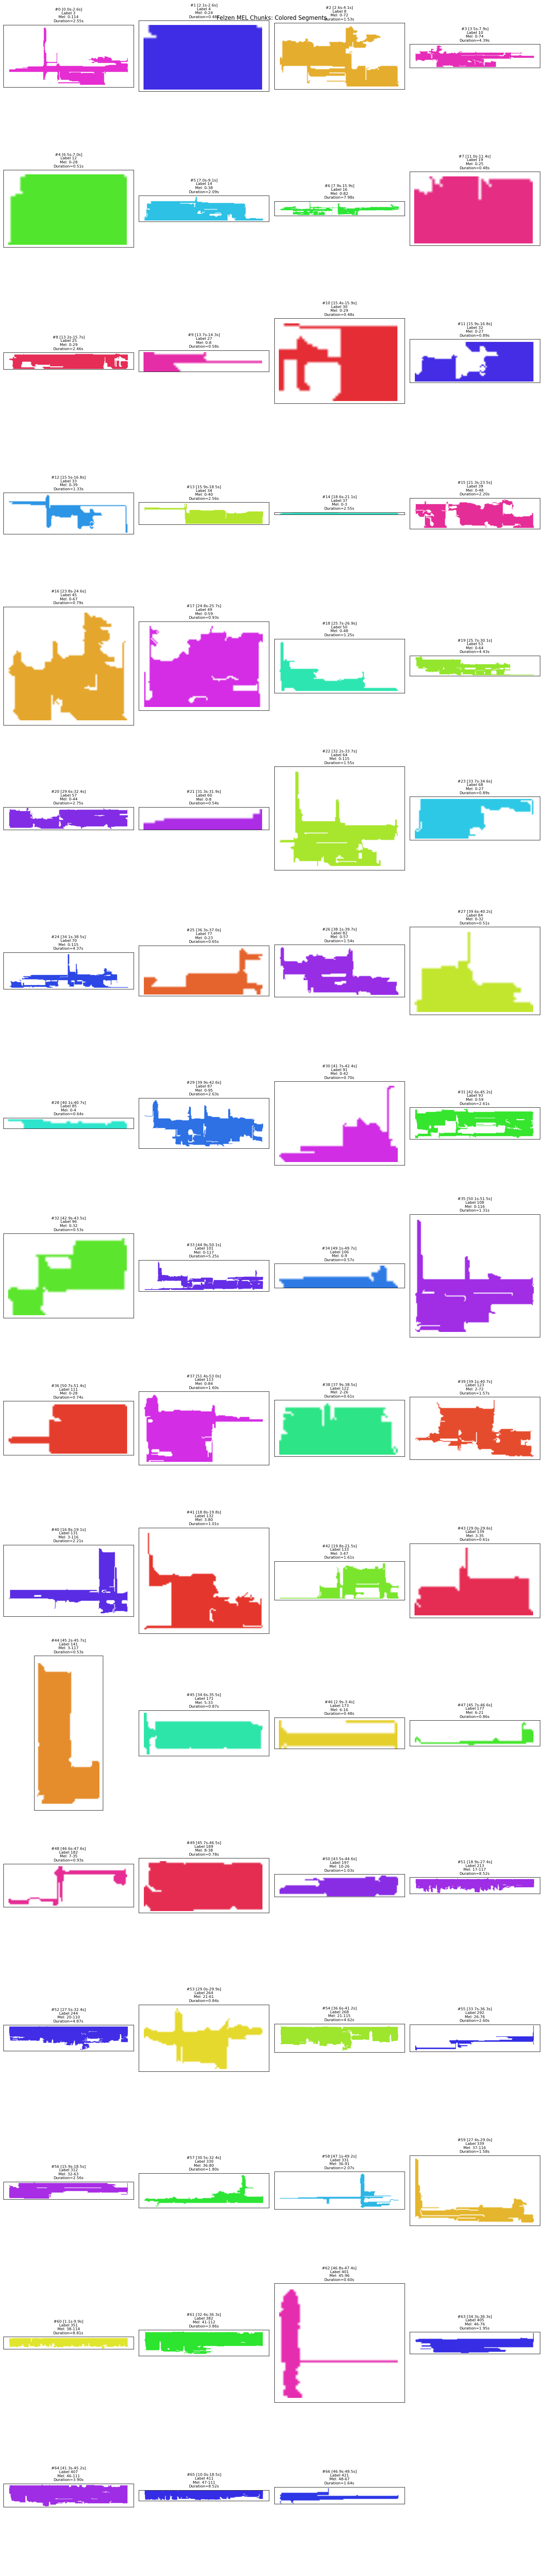


✅ Displayed 67 felzenszwalb MEL chunks with segment colors


In [39]:
# 🎨 GRID OF ALL FELZEN MEL CHUNKS FROM MEL SPECTROGRAM (COLORED)

# Re-load audio and recreate mel spectrogram to visualize chunks
y, sr = librosa.load(song_path, sr=None)
D = librosa.stft(y, n_fft=2048, hop_length=512, window="hann", center=True)
S = np.abs(D)

# Compute mel spectrogram
M = librosa.feature.melspectrogram(
    S=S, sr=sr, n_mels=128, fmin=0, fmax=None
)

# Recreate segmentation to get labels and colors
from skimage.util import img_as_ubyte
M_db = librosa.power_to_db(M, ref=np.max)
M_db_norm = (M_db - M_db.min()) / max(1e-12, (M_db.max() - M_db.min()))
img = img_as_ubyte(M_db_norm)
segments = felzenszwalb(img, scale=150, sigma=1, min_size=20)
unique_labels = np.unique(segments)

# Create the SAME color mapping as in the original visualization
# Use the same random seed to get identical shuffle
from matplotlib.colors import hsv_to_rgb
n_labels = len(unique_labels)
hsv_colors = [(i / n_labels, 0.8, 0.9) for i in range(n_labels)]
rgb_colors = [hsv_to_rgb(c) for c in hsv_colors]
np.random.seed(11)  # Fixed seed to match the mel segmentation
np.random.shuffle(rgb_colors)

# Create a mapping from label to color
label_to_color = {label: rgb_colors[i % len(rgb_colors)] for i, label in enumerate(unique_labels)}

# Use ALL segments to display
N = len(kept_segments)
segments_to_show = kept_segments

# Create grid with same layout
cols = 4
rows = int(np.ceil(N / cols))
fig_grid, axes_grid = plt.subplots(rows, cols, figsize=(cols * 4, rows * 4.5),
                                    subplot_kw={'aspect': 'auto'})
axes_grid = np.atleast_2d(axes_grid).reshape(rows, cols)

for idx in range(rows * cols):
    r = idx // cols
    c = idx % cols
    ax = axes_grid[r, c]

    if idx < N:
        seg = segments_to_show[idx]
        label = seg["label"]

        # Get the color for this segment's label
        color = label_to_color.get(label, (1, 1, 1))

        # Extract the chunk from the MEL spectrogram
        t0, t1 = seg["t0_frame"], seg["t1_frame"]
        mel_f0, mel_f1 = seg["mel_f0_bin"], seg["mel_f1_bin"]

        # Create mask for this segment
        chunk_mask = (segments == label)

        # Extract just this segment's region at FULL RESOLUTION
        chunk_region = chunk_mask[mel_f0:mel_f1+1, t0:t1+1]
        chunk_height, chunk_width = chunk_region.shape

        # Create RGB image with WHITE background at full resolution
        colored_chunk = np.ones((chunk_height, chunk_width, 3))
        colored_chunk[chunk_region] = color

        # Show the colored chunk at full resolution
        im = ax.imshow(colored_chunk, origin='lower', interpolation='bilinear')

        # Set white background for the axes
        ax.set_facecolor('white')

        # Zoom to fit this specific chunk with a small margin
        margin = 0.05  # 5% margin
        ax.set_xlim(-margin * chunk_width, chunk_width * (1 + margin))
        ax.set_ylim(-margin * chunk_height, chunk_height * (1 + margin))

        # Title with segment info - same format as original grid
        title = (f"#{idx} [{seg['t0_sec']:.1f}s-{seg['t1_sec']:.1f}s]\n"
                f"Label {label}\n"
                f"Mel: {seg['mel_f0_bin']}-{seg['mel_f1_bin']}\n"
                f"Duration={seg['time_span_sec']:.2f}s")
        ax.set_title(title, fontsize=8, linespacing=1.2)
        ax.set_xticks([])
        ax.set_yticks([])
    else:
        ax.axis('off')

fig_grid.suptitle("Felzen MEL Chunks: Colored Segments", fontsize=12)
plt.tight_layout()

# Save to PDF
output_dir = f"chunks_mel_{song_path.split('/')[-1].split('.')[0]}"
pdf_path_grid = os.path.join(output_dir, "06_felzen_mel_chunks_grid_colored.pdf")
plt.savefig(pdf_path_grid, format='pdf', bbox_inches='tight', dpi=300)
print(f"📄 Saved: {pdf_path_grid}")

plt.show()

print(f"\n✅ Displayed {N} felzenszwalb MEL chunks with segment colors")

📄 Saved: chunks_mel_plainte2/07_felzen_mel_chunks_grid_spectrogram.pdf


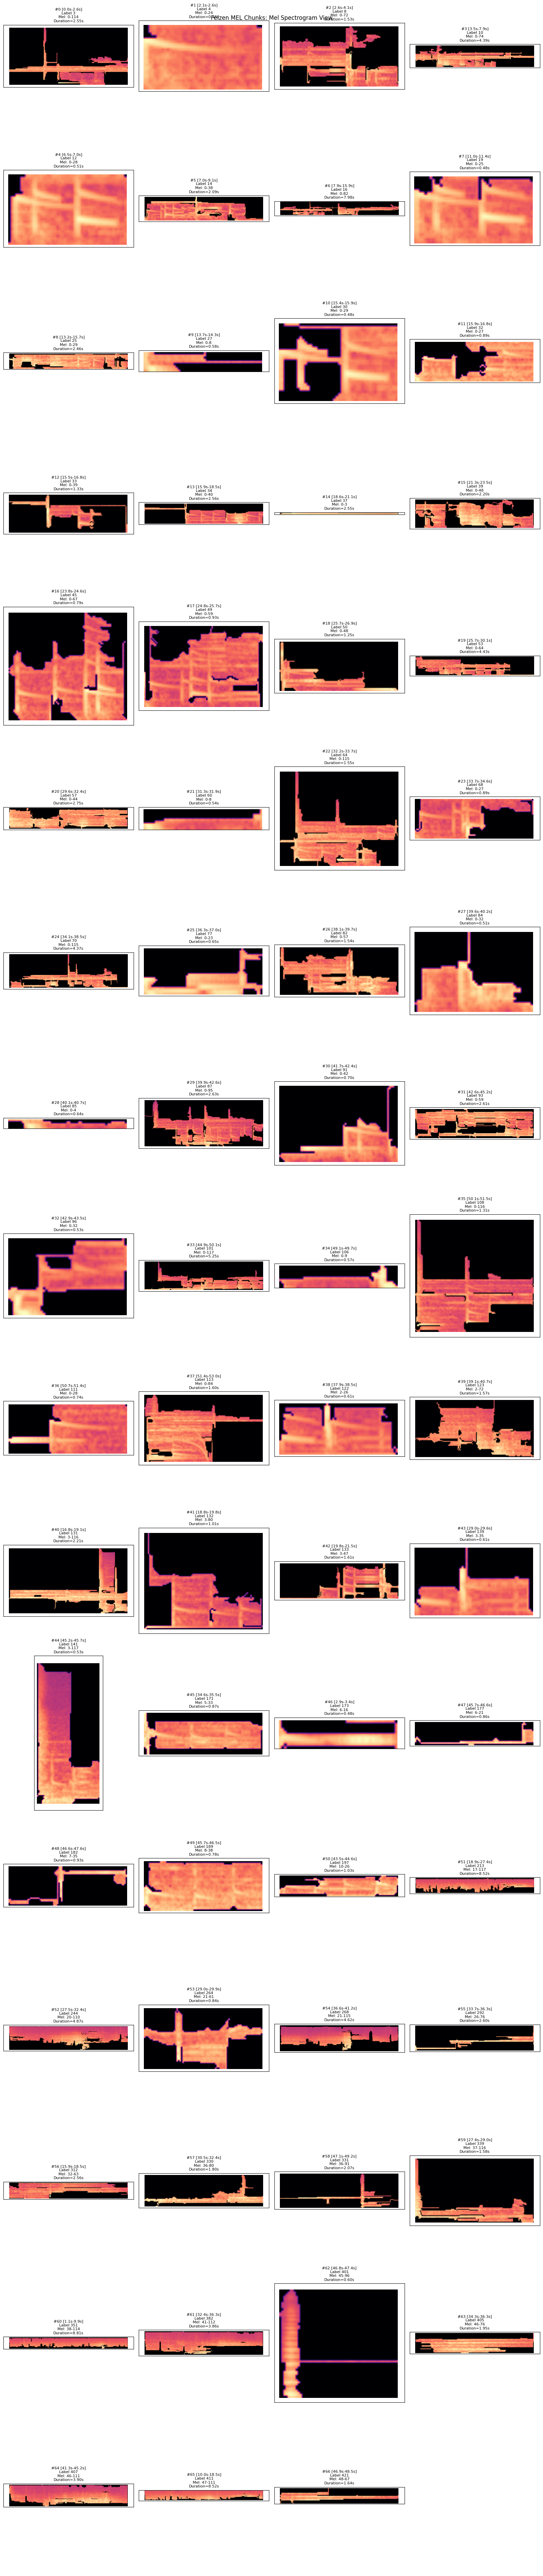


✅ Displayed 67 felzenszwalb MEL chunks with mel spectrogram data


In [40]:
# 🎨 GRID OF ALL FELZEN MEL CHUNKS - MEL SPECTROGRAM VIEW

# Create grid with same layout
cols = 4
rows = int(np.ceil(N / cols))
fig_spec, axes_spec = plt.subplots(rows, cols, figsize=(cols * 4, rows * 4.5),
                                    subplot_kw={'aspect': 'auto'})
axes_spec = np.atleast_2d(axes_spec).reshape(rows, cols)

for idx in range(rows * cols):
    r = idx // cols
    c = idx % cols
    ax = axes_spec[r, c]

    if idx < N:
        seg = segments_to_show[idx]
        label = seg["label"]

        # Extract the chunk from the MEL spectrogram
        t0, t1 = seg["t0_frame"], seg["t1_frame"]
        mel_f0, mel_f1 = seg["mel_f0_bin"], seg["mel_f1_bin"]

        # Create mask for this segment
        chunk_mask = (segments == label)

        # Extract just this segment's region at FULL RESOLUTION
        chunk_region = chunk_mask[mel_f0:mel_f1+1, t0:t1+1]
        chunk_height, chunk_width = chunk_region.shape

        # Extract MEL SPECTROGRAM data for this chunk
        chunk_spec = M_db[mel_f0:mel_f1+1, t0:t1+1].copy()

        # Mask out non-chunk areas (set to minimum value)
        chunk_spec[~chunk_region] = M_db.min()

        # Show the mel spectrogram chunk at full resolution (same settings as colored version)
        im = ax.imshow(chunk_spec, origin='lower', cmap='magma', interpolation='bilinear')

        # Set white background for the axes
        ax.set_facecolor('white')

        # Zoom to fit this specific chunk with a small margin (SAME as colored version)
        margin = 0.05  # 5% margin
        ax.set_xlim(-margin * chunk_width, chunk_width * (1 + margin))
        ax.set_ylim(-margin * chunk_height, chunk_height * (1 + margin))

        # Title with segment info - same format as curves grid
        title = (f"#{idx} [{seg['t0_sec']:.1f}s-{seg['t1_sec']:.1f}s]\n"
                f"Label {label}\n"
                f"Mel: {seg['mel_f0_bin']}-{seg['mel_f1_bin']}\n"
                f"Duration={seg['time_span_sec']:.2f}s")
        ax.set_title(title, fontsize=8, linespacing=1.2)
        ax.set_xticks([])
        ax.set_yticks([])
    else:
        ax.axis('off')

fig_spec.suptitle("Felzen MEL Chunks: Mel Spectrogram View", fontsize=12)
plt.tight_layout()

# Save to PDF
output_dir = f"chunks_mel_{song_path.split('/')[-1].split('.')[0]}"
pdf_path_spec = os.path.join(output_dir, "07_felzen_mel_chunks_grid_spectrogram.pdf")
plt.savefig(pdf_path_spec, format='pdf', bbox_inches='tight', dpi=300)
print(f"📄 Saved: {pdf_path_spec}")

plt.show()

print(f"\n✅ Displayed {N} felzenszwalb MEL chunks with mel spectrogram data")

/Users/mykqs/dev/fuites-anarchive/packages/compost/.venv/lib/python3.13/site-packages/librosa/core/pitch.py:103: UserWarning: Trying to estimate tuning from empty frequency set.
  return pitch_tuning(


📄 Saved: chunks_mel_plainte2/08_mel_path_hsva_colored.pdf


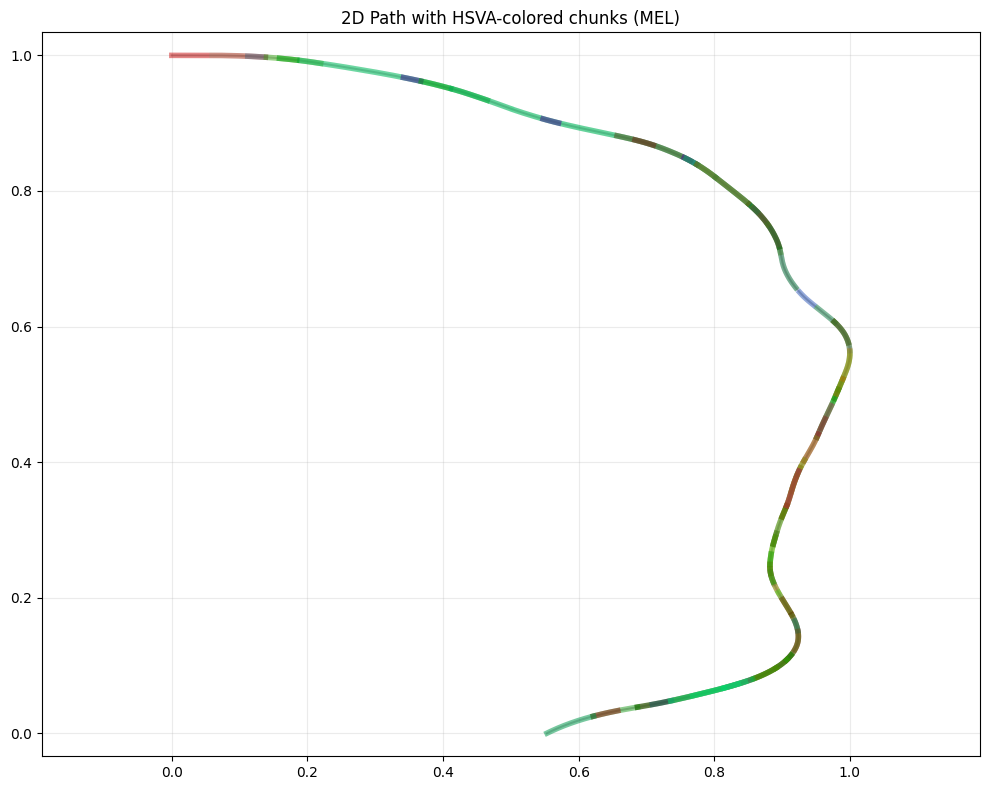

📄 Saved: chunks_mel_plainte2/09_mel_circle_of_fifths.pdf


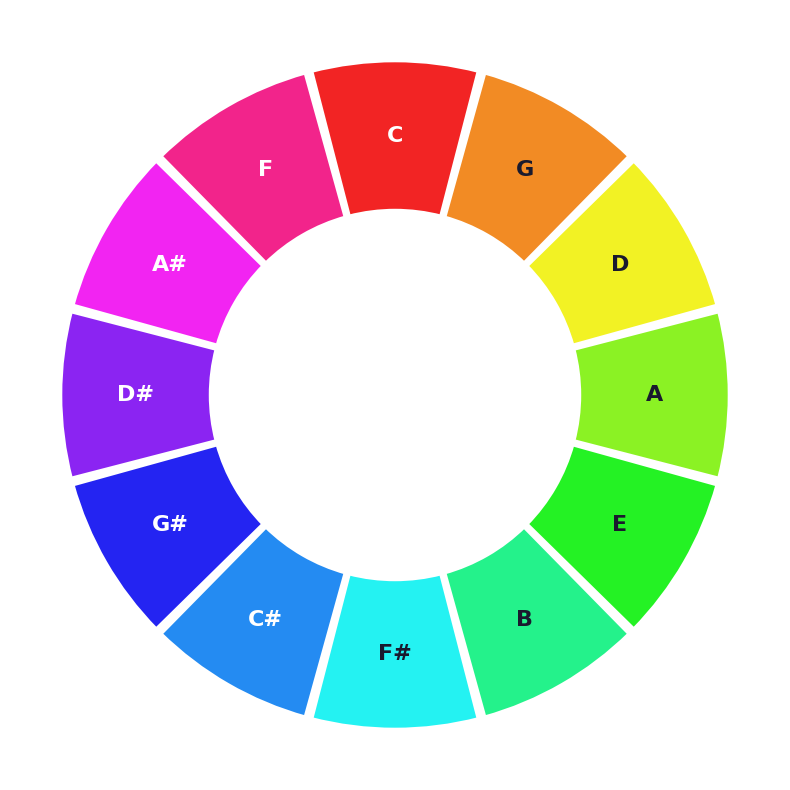

📄 Saved: chunks_mel_plainte2/10_mel_chunks_grid_hsva_labeled.pdf


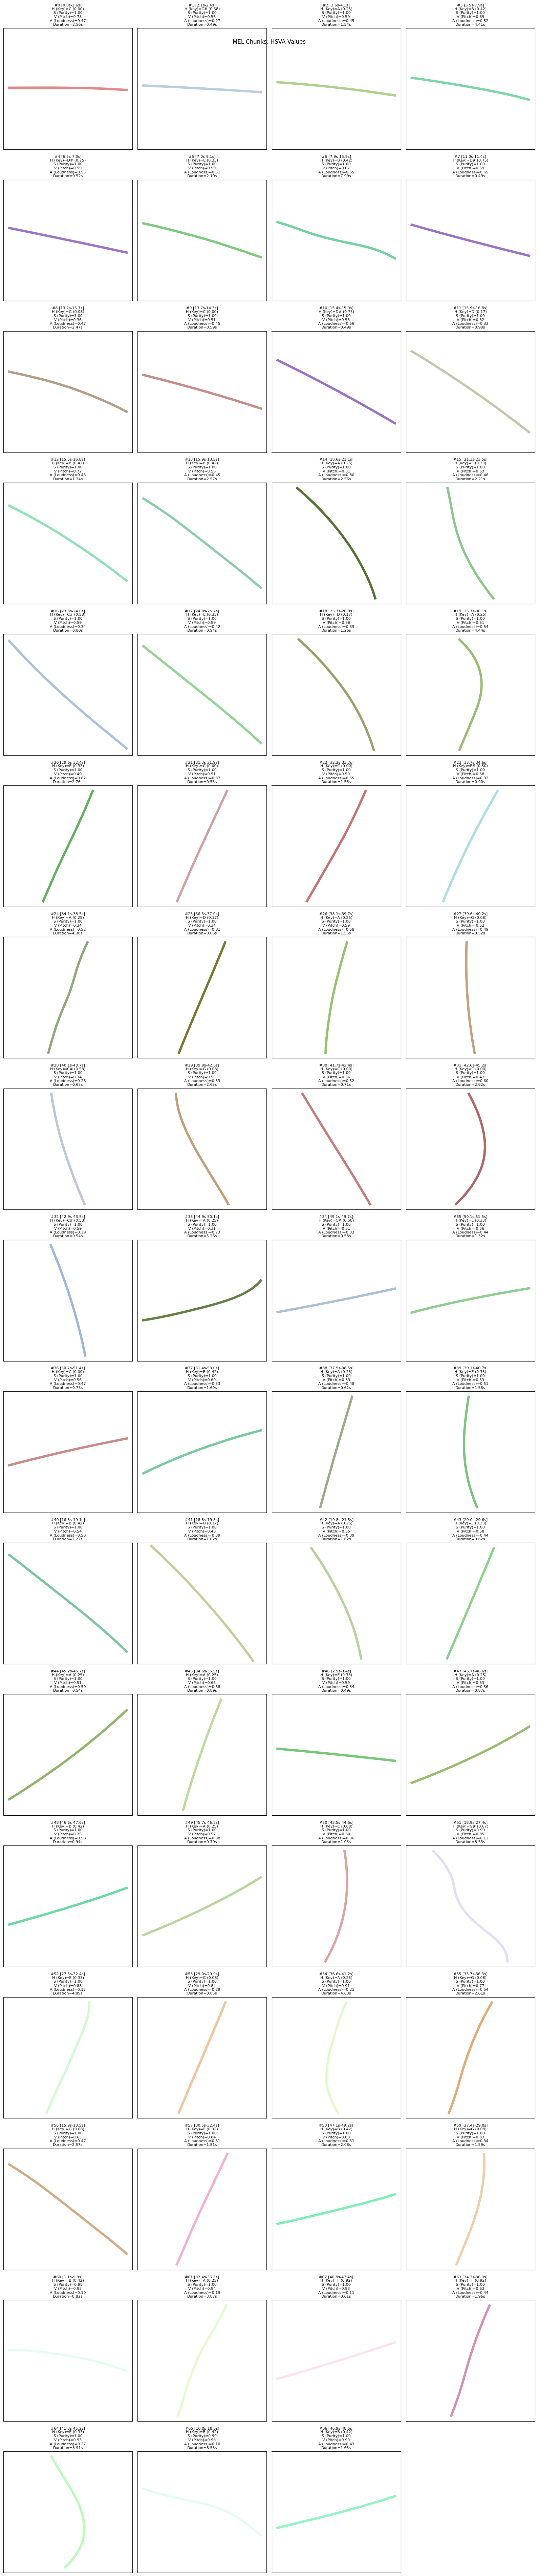

📄 Saved: chunks_mel_plainte2/11_mel_hsva_per_chunk.pdf


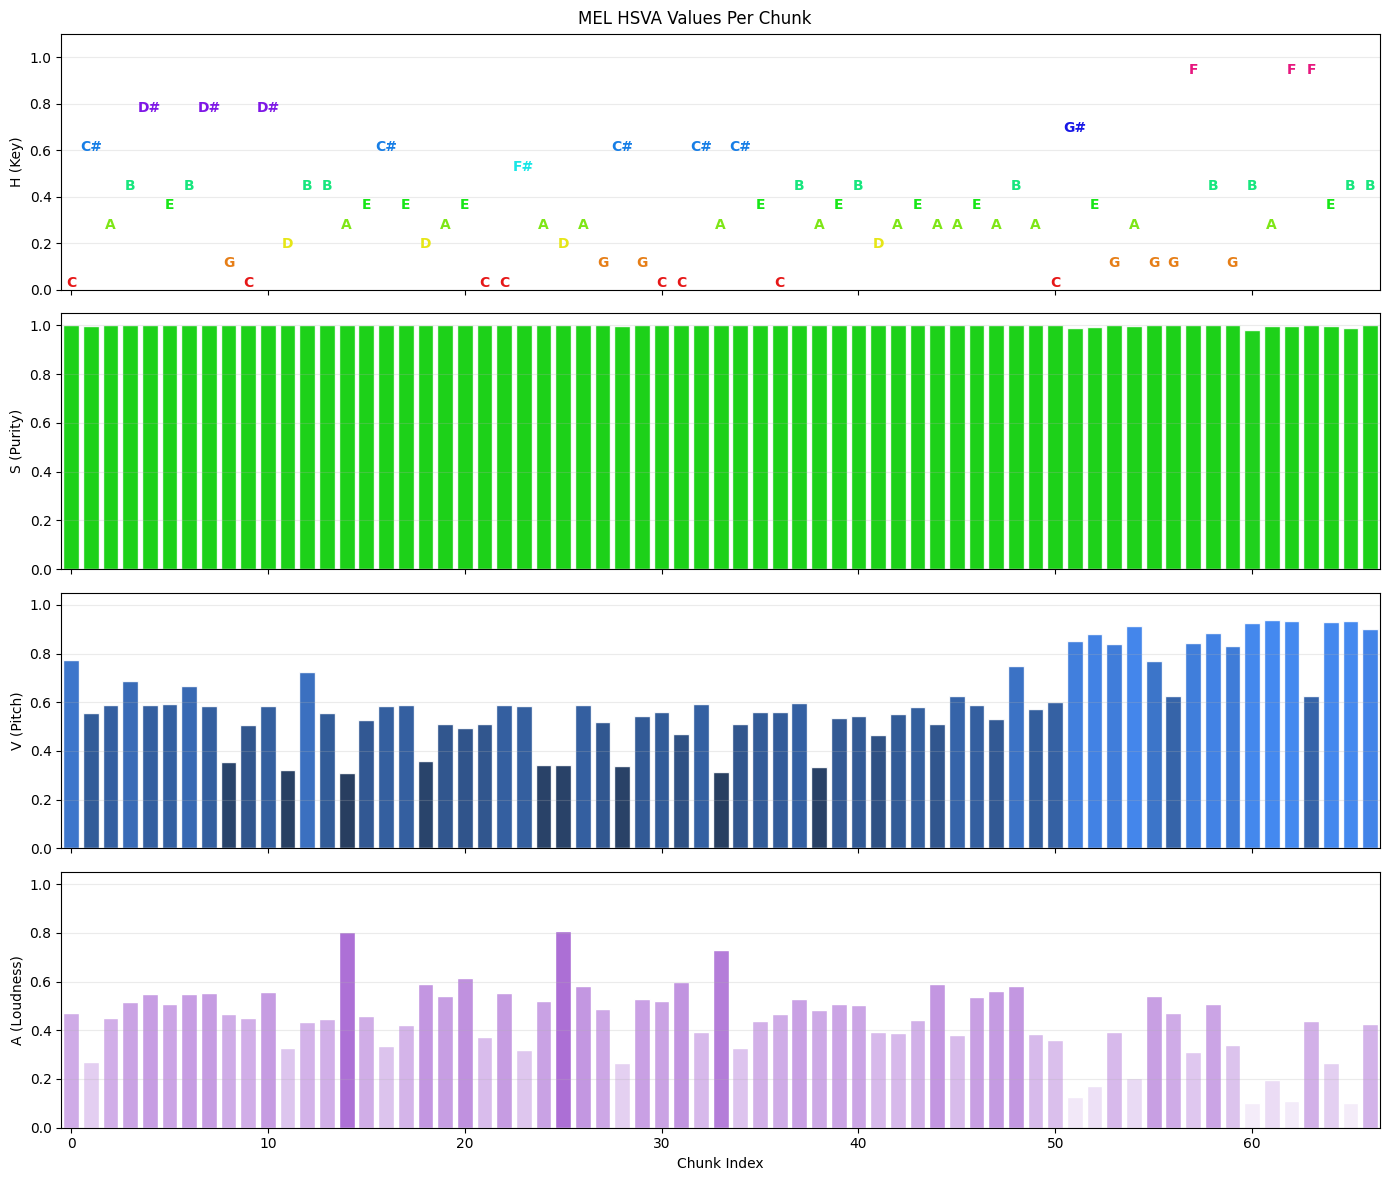

📄 Saved: chunks_mel_plainte2/12_mel_duration_per_chunk.pdf


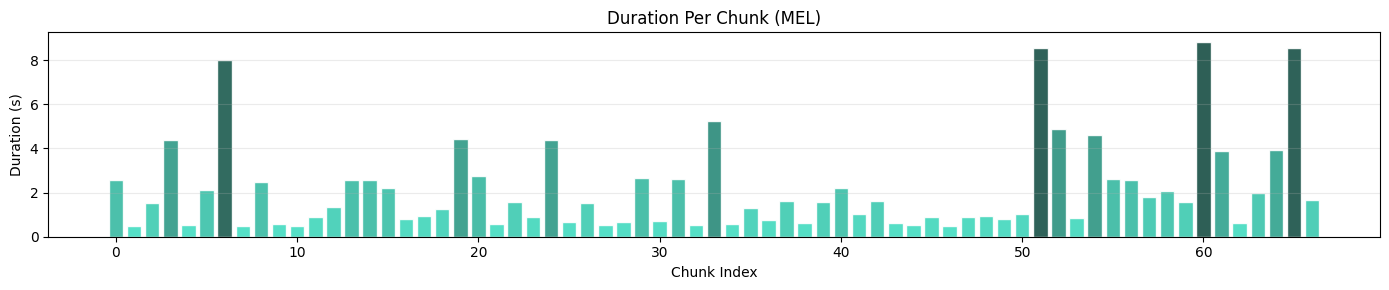


📊 MEL Summary (67 chunks):
   H (Key):      0.32
   S (Purity):   1.00
   V (Pitch):    0.61
   A (Loudness): 0.44
   Duration:     2.13s total=142.41s


In [41]:
import numpy as np
import matplotlib.pyplot as plt
import colorsys
import sys
sys.path.insert(0, '..')

from utils.sound_utils import create_2d_path_visualization
from matplotlib.patches import Wedge
import soundfile as sf

# Circle of fifths for key names
CIRCLE_ORDER = [0, 7, 2, 9, 4, 11, 6, 1, 8, 3, 10, 5]
PITCH_NAMES = ["C", "C#", "D", "D#", "E", "F", "F#", "G", "G#", "A", "A#", "B"]

def hue_to_key_name(h):
    idx = int(h * 12) % 12
    pitch_idx = CIRCLE_ORDER[idx]
    return PITCH_NAMES[pitch_idx]

# Run visualization for MEL segments
X, Y, curve_chunks_2d, curve_profiles_2d = create_2d_path_visualization(
    kept_segments,  # Using mel kept_segments
    song_path,
    points_per_second=100,
    resampled_points_per_chunk=128,
    show_plots=False
)

for i, chunk in enumerate(curve_chunks_2d):
    seg = kept_segments[i]
    chunk["duration"] = seg["t1_sec"] - seg["t0_sec"]

overlay_idxs = list(range(min(100, len(curve_chunks_2d))))

# Setup output directory
output_dir = f"chunks_mel_{song_path.split('/')[-1].split('.')[0]}"

# Figure 1: Full path
fig1, ax1 = plt.subplots(1, 1, figsize=(10, 8))
ax1.plot(X, Y, color="#333", linewidth=1.5, alpha=0.3)
for i in overlay_idxs:
    chunk = curve_chunks_2d[i]
    ax1.plot(chunk["x"], chunk["y"], linewidth=4.0, color=chunk["color_rgba"])
ax1.set_title("2D Path with HSVA-colored chunks (MEL)")
ax1.axis('equal')
ax1.grid(True, alpha=0.25)
plt.tight_layout()
pdf_path_1 = os.path.join(output_dir, "08_mel_path_hsva_colored.pdf")
plt.savefig(pdf_path_1, format='pdf', bbox_inches='tight', dpi=300)
print(f"📄 Saved: {pdf_path_1}")
plt.show()

# Figure 2: Circle of fifths
fig_cof, ax_cof = plt.subplots(1, 1, figsize=(8, 8), facecolor='#FFFFFF')
ax_cof.set_facecolor('#FFFFFF')

R_outer, R_inner = 1.0, 0.55

for k in range(12):
    pitch = CIRCLE_ORDER[k]
    H = k / 12.0
    r_col, g_col, b_col = colorsys.hsv_to_rgb(H, 0.85, 0.95)

    theta_center = 90.0 - k * 30.0
    theta1, theta2 = theta_center - 14.5, theta_center + 14.5

    # Wedge
    wedge = Wedge((0, 0), R_outer, theta1, theta2, width=R_outer - R_inner,
                facecolor=(r_col, g_col, b_col), edgecolor='#FFFFFF', linewidth=3)
    ax_cof.add_patch(wedge)

    # Letter inside wedge
    theta_mid = np.deg2rad(theta_center)
    r_text = (R_outer + R_inner) / 2
    tx, ty = r_text * np.cos(theta_mid), r_text * np.sin(theta_mid)

    brightness = 0.299 * r_col + 0.587 * g_col + 0.114 * b_col
    text_color = '#1a1a2e' if brightness > 0.6 else 'white'

    ax_cof.text(tx, ty, PITCH_NAMES[pitch], ha='center', va='center',
                fontsize=16, fontweight='bold', color=text_color)


ax_cof.set_xlim(-1.15, 1.15)
ax_cof.set_ylim(-1.15, 1.15)
ax_cof.set_aspect('equal')
ax_cof.axis('off')
plt.tight_layout()
pdf_path_2 = os.path.join(output_dir, "09_mel_circle_of_fifths.pdf")
plt.savefig(pdf_path_2, format='pdf', bbox_inches='tight', dpi=300)
print(f"📄 Saved: {pdf_path_2}")
plt.show()


# Figure 3: Grid with HSVA labels
N = len(overlay_idxs)
if N > 0:
    cols = 4
    rows = int(np.ceil(N / cols))
    fig2, axes2 = plt.subplots(rows, cols, figsize=(cols * 4, rows * 4.5))
    axes2 = np.atleast_2d(axes2).reshape(rows, cols)

    for idx in range(rows * cols):
        r = idx // cols
        c = idx % cols
        ax = axes2[r, c]

        if idx < N:
            k = overlay_idxs[idx]
            chunk = curve_chunks_2d[k]
            rgba = chunk["color_rgba"]
            r_val, g_val, b_val, a_val = rgba
            h, s, v = colorsys.rgb_to_hsv(r_val, g_val, b_val)
            key_name = hue_to_key_name(h)

            ax.plot(chunk["x_resampled"], chunk["y_resampled"], color=rgba, linewidth=5.0)

            title = (
                f"#{k} [{chunk['t_start']:.1f}s-{chunk['t_end']:.1f}s]\n"
                f"H (Key)={key_name} ({h:.2f})\n"
                f"S (Purity)={s:.2f}\n"
                f"V (Pitch)={v:.2f}\n"
                f"A (Loudness)={a_val:.2f}\n"
                f"Duration={chunk['duration']:.2f}s"
            )
            ax.set_title(title, fontsize=8, linespacing=1.2)
            ax.axis('equal')
            ax.grid(True, alpha=0.25)
            ax.set_xticks([])
            ax.set_yticks([])
        else:
            ax.axis('off')

    fig2.suptitle("MEL Chunks: HSVA Values", fontsize=12)
    plt.tight_layout()
    pdf_path_3 = os.path.join(output_dir, "10_mel_chunks_grid_hsva_labeled.pdf")
    plt.savefig(pdf_path_3, format='pdf', bbox_inches='tight', dpi=300)
    print(f"📄 Saved: {pdf_path_3}")
    plt.show()

# Collect HSVA data
chunk_ids = list(range(len(curve_chunks_2d)))
hsva_data = []
key_names_list = []
for chunk in curve_chunks_2d:
    r_val, g_val, b_val, a_val = chunk["color_rgba"]
    h, s, v = colorsys.rgb_to_hsv(r_val, g_val, b_val)
    hsva_data.append((h, s, v, a_val))
    key_names_list.append(hue_to_key_name(h))
hsva_data = np.array(hsva_data)

# Figure 4: HSVA per chunk
fig3, axes3 = plt.subplots(4, 1, figsize=(14, 12), sharex=True)

# Hue - colored key letters
ax_h = axes3[0]
for j, (h_val, key) in enumerate(zip(hsva_data[:, 0], key_names_list)):
    color = colorsys.hsv_to_rgb(h_val, 0.9, 0.9)
    ax_h.text(j, h_val, key, ha='center', va='bottom', fontsize=10, fontweight='bold', color=color)
ax_h.set_xlim(-0.5, len(chunk_ids) - 0.5)
ax_h.set_ylim(0, 1.1)
ax_h.set_ylabel('H (Key)')
ax_h.grid(True, alpha=0.25, axis='y')

# Saturation - gray to green
sat_colors = [colorsys.hsv_to_rgb(0.33, s, 0.8) for s in hsva_data[:, 1]]
axes3[1].bar(chunk_ids, hsva_data[:, 1], color=sat_colors, edgecolor='white', alpha=0.9)
axes3[1].set_ylabel('S (Purity)')
axes3[1].set_ylim(0, 1.05)
axes3[1].grid(True, alpha=0.25, axis='y')

# Value - dark to bright blue
val_colors = [colorsys.hsv_to_rgb(0.6, 0.8, v) for v in hsva_data[:, 2]]
axes3[2].bar(chunk_ids, hsva_data[:, 2], color=val_colors, edgecolor='white', alpha=0.9)
axes3[2].set_ylabel('V (Pitch)')
axes3[2].set_ylim(0, 1.05)
axes3[2].grid(True, alpha=0.25, axis='y')

# Alpha - transparent to opaque purple
alpha_colors = [(0.6, 0.3, 0.8, a) for a in hsva_data[:, 3]]
axes3[3].bar(chunk_ids, hsva_data[:, 3], color=alpha_colors, edgecolor='white')
axes3[3].set_ylabel('A (Loudness)')
axes3[3].set_ylim(0, 1.05)
axes3[3].set_xlabel('Chunk Index')
axes3[3].grid(True, alpha=0.25, axis='y')

fig3.suptitle("MEL HSVA Values Per Chunk", fontsize=12)
plt.tight_layout()
pdf_path_4 = os.path.join(output_dir, "11_mel_hsva_per_chunk.pdf")
plt.savefig(pdf_path_4, format='pdf', bbox_inches='tight', dpi=300)
print(f"📄 Saved: {pdf_path_4}")
plt.show()

# Figure 5: Duration - dark if high
fig4, ax4 = plt.subplots(figsize=(14, 3))
durations = [chunk["duration"] for chunk in curve_chunks_2d]
max_dur = max(durations)
dur_colors = [colorsys.hsv_to_rgb(0.47, 0.7, 0.9 - 0.6 * (d / max_dur)) for d in durations]  # dark if high
ax4.bar(chunk_ids, durations, color=dur_colors, edgecolor='white', alpha=0.9)
ax4.set_ylabel('Duration (s)')
ax4.set_xlabel('Chunk Index')
ax4.grid(True, alpha=0.25, axis='y')
ax4.set_title("Duration Per Chunk (MEL)")
plt.tight_layout()
pdf_path_5 = os.path.join(output_dir, "12_mel_duration_per_chunk.pdf")
plt.savefig(pdf_path_5, format='pdf', bbox_inches='tight', dpi=300)
print(f"📄 Saved: {pdf_path_5}")
plt.show()

print(f"\n📊 MEL Summary ({len(curve_chunks_2d)} chunks):")
print(f"   H (Key):      {np.mean(hsva_data[:,0]):.2f}")
print(f"   S (Purity):   {np.mean(hsva_data[:,1]):.2f}")
print(f"   V (Pitch):    {np.mean(hsva_data[:,2]):.2f}")
print(f"   A (Loudness): {np.mean(hsva_data[:,3]):.2f}")
print(f"   Duration:     {np.mean(durations):.2f}s total={sum(durations):.2f}s")